In [160]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as ss
import time
import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder, StandardScaler, OneHotEncoder, MultiLabelBinarizer
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif, SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, classification_report, confusion_matrix

RANDOM_STATE = 42
TEST_SIZE = 0.2
TARGET = "JobSatLevel"
DATA_PATH = "train_data.csv"
SCHEMA_PATH = "survey_results_schema.csv"

preprocessing_objects = {}
target_order = ["Low", "Average", "High"]
target_mapping = {level: i for i, level in enumerate(target_order)}

In [161]:
df_raw = pd.read_csv(DATA_PATH, low_memory=False)
print("Original shape:", df_raw.shape)


data = df_raw.dropna(subset=[TARGET]).copy()
print("Rows after dropping null target:", data.shape)

print("Duplicate rows:", data.duplicated().sum())
data = data.drop_duplicates().dropna(how="all").reset_index(drop=True)
print("Shape after dropping duplicates/all-empty rows:", data.shape)

print("Target distribution:")
print(data[TARGET].value_counts().reindex(target_order))

Original shape: (44196, 156)
Rows after dropping null target: (23961, 156)
Duplicate rows: 0
Shape after dropping duplicates/all-empty rows: (23961, 156)
Target distribution:
JobSatLevel
Low         6803
Average    11296
High        5862
Name: count, dtype: int64


In [162]:

schema = pd.read_csv(SCHEMA_PATH)
link = dict(zip(schema["qname"], schema["question"]))
print(f"Schema loaded. Matched descriptions for {sum(c in link for c in data.columns)} columns.")
link

Schema loaded. Matched descriptions for 109 columns.


{'TechEndorse_1': 'What attracts you to a technology or causes you to endorse it (most to least important)?',
 'TechEndorse_2': 'What attracts you to a technology or causes you to endorse it (most to least important)?',
 'TechEndorse_3': 'What attracts you to a technology or causes you to endorse it (most to least important)?',
 'TechEndorse_4': 'What attracts you to a technology or causes you to endorse it (most to least important)?',
 'TechEndorse_5': 'What attracts you to a technology or causes you to endorse it (most to least important)?',
 'TechEndorse_6': 'What attracts you to a technology or causes you to endorse it (most to least important)?',
 'TechEndorse_7': 'What attracts you to a technology or causes you to endorse it (most to least important)?',
 'TechEndorse_8': 'What attracts you to a technology or causes you to endorse it (most to least important)?',
 'TechEndorse_9': 'What attracts you to a technology or causes you to endorse it (most to least important)?',
 'TechEndo

In [163]:
print("Number of columns:", len(data.columns))
print("Dtype counts:")
print(data.dtypes.value_counts())

missing_overview = (
    data.isnull().mean().mul(100).sort_values(ascending=False)
    .rename("missing_percent")
    .to_frame()
)
display(missing_overview.head(20))

Number of columns: 156
Dtype counts:
object     120
float64     36
Name: count, dtype: int64


,missing_percent
AIAgentObsWrite,99.348942
SOTagsWant Entry,99.027586
SOTagsHaveEntry,98.944118
AIModelsWantEntry,98.802220
AIAgentOrchWrite,98.710404
AIModelsHaveEntry,97.929970
AIAgentKnowWrite,97.929970
SO_Actions_15_TEXT,97.875715
AIAgentExtWrite,97.408288
CommPlatformWantEntr,97.066066


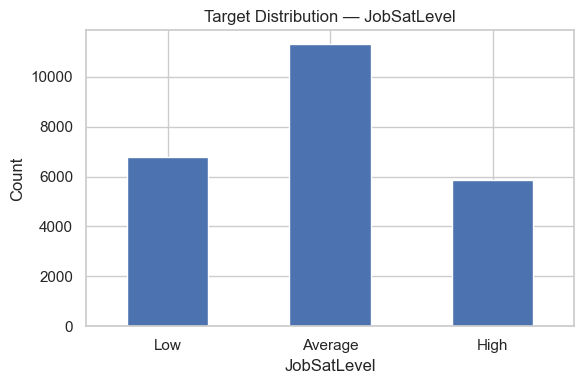

In [164]:
fig = plt.figure(figsize=(6, 4))
data[TARGET].value_counts().reindex(target_order).plot(kind="bar")
plt.title("Target Distribution — JobSatLevel")
plt.xlabel("JobSatLevel")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [165]:

all_ai_cols = [c for c in data.columns if c.startswith("AI")]
first_21_ai_cols = all_ai_cols[:21]
main_extra_cols = ["WorkExp", "NewRole", "LearnCodeAI", "LearnCode"]
main_ai_cols = [c for c in first_21_ai_cols + main_extra_cols + [TARGET] if c in data.columns]

print("AI columns found:", len(all_ai_cols))
print("First 21 AI columns used by main notebook:")
print(first_21_ai_cols)
print("Main AI block columns:")
print(main_ai_cols)

AI columns found: 42
First 21 AI columns used by main notebook:
['AILearnHow', 'AIThreat', 'AIModelsChoice', 'AIModelsHaveWorkedWith', 'AIModelsWantToWorkWith', 'AIModelsAdmired', 'AIModelsHaveEntry', 'AIModelsWantEntry', 'AISelect', 'AISent', 'AIAcc', 'AIComplex', 'AIToolCurrently partially AI', "AIToolDon't plan to use AI for this task", 'AIToolPlan to partially use AI', 'AIToolPlan to mostly use AI', 'AIToolCurrently mostly AI', 'AIFrustration', 'AIExplain', 'AIAgents', 'AIAgentChange']
Main AI block columns:
['AILearnHow', 'AIThreat', 'AIModelsChoice', 'AIModelsHaveWorkedWith', 'AIModelsWantToWorkWith', 'AIModelsAdmired', 'AIModelsHaveEntry', 'AIModelsWantEntry', 'AISelect', 'AISent', 'AIAcc', 'AIComplex', 'AIToolCurrently partially AI', "AIToolDon't plan to use AI for this task", 'AIToolPlan to partially use AI', 'AIToolPlan to mostly use AI', 'AIToolCurrently mostly AI', 'AIFrustration', 'AIExplain', 'AIAgents', 'AIAgentChange', 'WorkExp', 'NewRole', 'LearnCodeAI', 'LearnCode', '

,WorkExp
count,23362.000000
mean,13.498202
std,10.050854
min,1.000000
25%,5.000000
50%,11.000000
75%,20.000000
max,100.000000


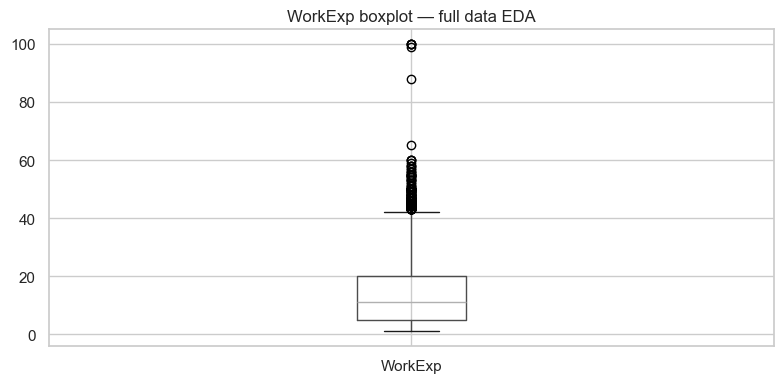

In [166]:

display(data[["WorkExp"]].describe())
plt.figure(figsize=(8, 4))
data.boxplot(column="WorkExp")
plt.title("WorkExp boxplot — full data EDA")
plt.tight_layout()
plt.show()

,feature_group,n_columns,avg_missing_%,max_missing_%,avg_cardinality,max_cardinality
1,AI agent + developer profile,27,57.74,99.35,709.85,13884
3,Stack Overflow community,18,39.72,99.03,281.56,1678
4,Tools + environments + platforms + OS,23,39.36,97.07,1893.43,5932
0,AI usage + work experience,25,31.53,98.80,1137.32,7698
2,Compensation + technology attitude,26,15.08,95.93,171.73,2226


,feature,missing_%,unique_values,dtype
41,AIAgentObsWrite,99.35,119,object
80,SOTagsWant Entry,99.03,202,object
79,SOTagsHaveEntry,98.94,223,object
7,AIModelsWantEntry,98.80,180,object
39,AIAgentOrchWrite,98.71,214,object
37,AIAgentKnowWrite,97.93,367,object
6,AIModelsHaveEntry,97.93,305,object
93,SO_Actions_15_TEXT,97.88,471,object
43,AIAgentExtWrite,97.41,308,object
112,CommPlatformWantEntr,97.07,349,object


<Figure size 1000x500 with 0 Axes>

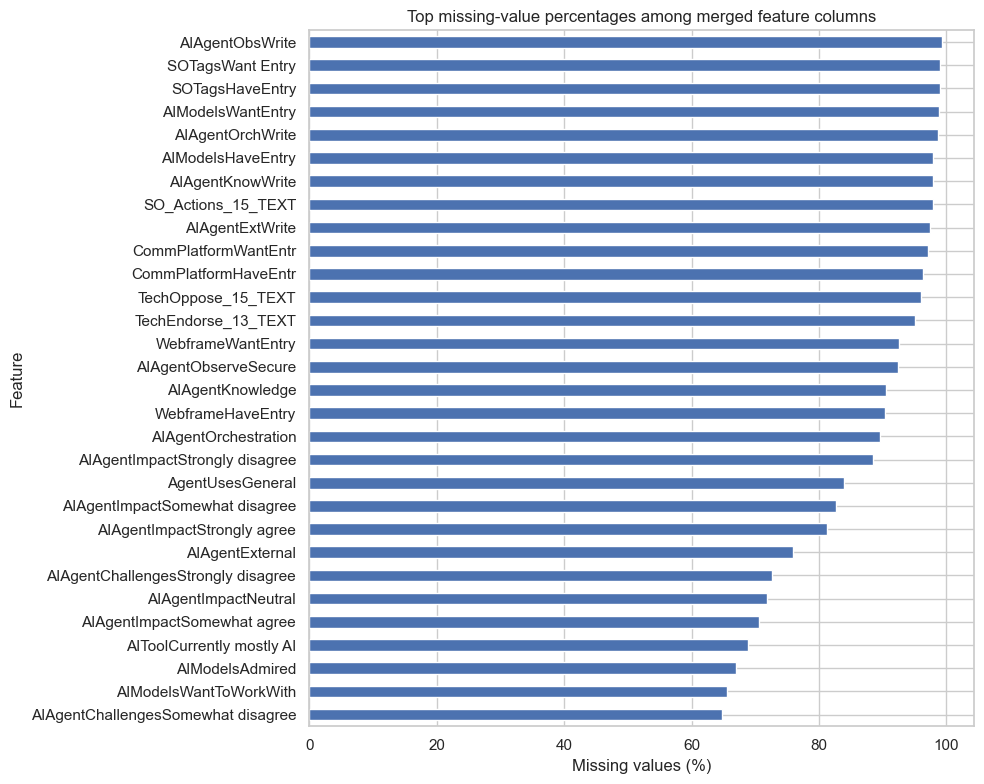

In [167]:


ai_usage_cols_eda = [c for c in first_21_ai_cols + main_extra_cols if c in data.columns]
ai_agent_cols_eda = [c for c in data.columns if c.startswith("AIAgent") or c == "AIHuman"] + [c for c in ["ICorPM", "YearsCode", "DevType", "OrgSize", "AIOpen"] if c in data.columns]
compensation_cols_eda = [c for c in ["Country", "Currency", "CompTotal", "TechEndorseIntro"] if c in data.columns]
compensation_cols_eda += [c for c in data.columns if c.startswith("TechEndorse_") or c.startswith("TechOppose_")]
stackoverflow_cols_eda = [c for c in [
    "SOTagsHaveWorkedWith", "SOTagsWantToWorkWith", "SOTagsAdmired", "SOTagsHaveEntry", "SOTagsWant Entry",
    "SOAccount", "SOVisitFreq", "SOPartFreq", "SOComm", "SOFriction", "SO_Actions_1", "SO_Actions_16",
    "SO_Actions_3", "SO_Actions_4", "SO_Actions_6", "SO_Actions_7", "SO_Actions_15", "SO_Actions_15_TEXT"
] if c in data.columns]
tools_platform_cols_eda = [c for c in data.columns if c.startswith(("Tool", "DevEnvs", "Webframe", "CommPlat", "CommPlatform", "OpSys"))]
tools_platform_cols_eda += [c for c in ["PurchaseInfluence", "EmploymentAddl", "Industry", "AgentUsesGeneral"] if c in data.columns]

eda_groups = {
    "AI usage + work experience": ai_usage_cols_eda,
    "AI agent + developer profile": ai_agent_cols_eda,
    "Compensation + technology attitude": compensation_cols_eda,
    "Stack Overflow community": stackoverflow_cols_eda,
    "Tools + environments + platforms + OS": tools_platform_cols_eda,
}

summary_rows = []
for group_name, cols in eda_groups.items():
    cols = list(dict.fromkeys(cols))
    if not cols:
        continue
    missing = data[cols].isna().mean().mul(100)
    cardinality = data[cols].nunique(dropna=True)
    summary_rows.append({
        "feature_group": group_name,
        "n_columns": len(cols),
        "avg_missing_%": round(missing.mean(), 2),
        "max_missing_%": round(missing.max(), 2),
        "avg_cardinality": round(cardinality.mean(), 2),
        "max_cardinality": int(cardinality.max()),
    })

eda_group_summary = pd.DataFrame(summary_rows).sort_values("avg_missing_%", ascending=False)
display(eda_group_summary)

all_eda_cols = list(dict.fromkeys(sum(eda_groups.values(), [])))
missing_cardinality_table = pd.DataFrame({
    "feature": all_eda_cols,
    "missing_%": [round(data[c].isna().mean() * 100, 2) for c in all_eda_cols],
    "unique_values": [data[c].nunique(dropna=True) for c in all_eda_cols],
    "dtype": [str(data[c].dtype) for c in all_eda_cols],
}).sort_values(["missing_%", "unique_values"], ascending=[False, False])

display(missing_cardinality_table.head(40))

plt.figure(figsize=(10, 5))
missing_cardinality_table.head(30).sort_values("missing_%").plot(
    x="feature", y="missing_%", kind="barh", legend=False, figsize=(10, 8)
)
plt.title("Top missing-value percentages among merged feature columns")
plt.xlabel("Missing values (%)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


AI usage / work-experience columns used for EDA:
['AILearnHow', 'AIThreat', 'AIModelsChoice', 'AIModelsHaveWorkedWith', 'AIModelsWantToWorkWith', 'AIModelsAdmired', 'AIModelsHaveEntry', 'AIModelsWantEntry', 'AISelect', 'AISent', 'AIAcc', 'AIComplex', 'AIToolCurrently partially AI', "AIToolDon't plan to use AI for this task", 'AIToolPlan to partially use AI', 'AIToolPlan to mostly use AI', 'AIToolCurrently mostly AI', 'AIFrustration', 'AIExplain', 'AIAgents', 'AIAgentChange', 'WorkExp', 'NewRole', 'LearnCodeAI', 'LearnCode']


,feature,value,count
0,AILearnHow,AI CodeGen tools or AI-enabled apps,1416
1,AILearnHow,"Other online resources (e.g. standard search, ...",501
2,AILearnHow,Colleague or on-the-job training,495
3,AILearnHow,Technical documentation (is generated for/by t...,347
4,AILearnHow,AI CodeGen tools or AI-enabled apps;Other onli...,339
...,...,...,...
75,AISent,Unsure,379
76,AIAcc,Somewhat trust,6568
77,AIAcc,Somewhat distrust,5864
78,AIAcc,Neither trust nor distrust,4782


Detected multi-choice AI usage columns: ['AILearnHow', 'AIModelsHaveWorkedWith', 'AIModelsWantToWorkWith', 'AIModelsAdmired', 'AIToolCurrently partially AI', "AIToolDon't plan to use AI for this task", 'AIToolPlan to partially use AI', 'AIToolPlan to mostly use AI', 'AIToolCurrently mostly AI', 'AIFrustration', 'AIExplain', 'LearnCode']


,AILearnHow,count
0,AI CodeGen tools or AI-enabled apps,8663
1,"Other online resources (e.g. standard search, ...",7212
2,Technical documentation (is generated for/by t...,7131
3,Videos (not associated with specific online co...,6295
4,Blogs or podcasts,4873
5,Colleague or on-the-job training,3759
6,Stack Overflow or Stack Exchange,2635
7,Online Courses or Certification (includes all ...,2437
8,Books / Physical media,1234
9,"School (i.e., University, College, etc)",670


,AIModelsHaveWorkedWith,count
0,openAI GPT (chatbot models),9406
1,Anthropic: Claude Sonnet,5208
2,Gemini (Flash general purpose models),3965
3,openAI Reasoning models,3903
4,openAI Image generating models,2987
5,Gemini (Pro Reasoning models),2916
6,DeepSeek (R- Reasoning models),2528
7,Meta Llama (all models),2040
8,DeepSeek (V- General purpose models),1544
9,Mistral AI models,1185


,AIModelsWantToWorkWith,count
0,openAI GPT (chatbot models),5839
1,Anthropic: Claude Sonnet,3971
2,openAI Reasoning models,2915
3,Gemini (Flash general purpose models),2599
4,Gemini (Pro Reasoning models),2570
5,openAI Image generating models,2091
6,DeepSeek (R- Reasoning models),1795
7,Meta Llama (all models),1368
8,DeepSeek (V- General purpose models),1184
9,X Grok models,930


,AIModelsAdmired,count
0,openAI GPT (chatbot models),5769
1,Anthropic: Claude Sonnet,3534
2,openAI Reasoning models,2510
3,Gemini (Flash general purpose models),2205
4,Gemini (Pro Reasoning models),1920
5,openAI Image generating models,1793
6,DeepSeek (R- Reasoning models),1293
7,Meta Llama (all models),961
8,DeepSeek (V- General purpose models),777
9,X Grok models,610


,AIToolCurrently partially AI,count
0,Writing code,8782
1,Search for answers,8123
2,Learning new concepts or technologies,6854
3,Debugging or fixing code,6814
4,Learning about a codebase,4662
5,Documenting code,4512
6,Generating content or synthetic data,4181
7,Testing code,4140
8,Creating or maintaining documentation,4005
9,Committing and reviewing code,3281


,AIToolDon't plan to use AI for this task,count
0,Deployment and monitoring,13117
1,Project planning,12121
2,Predictive analytics,11314
3,Committing and reviewing code,9897
4,Testing code,7135
5,Learning about a codebase,6642
6,Creating or maintaining documentation,6478
7,Documenting code,6241
8,Generating content or synthetic data,6225
9,Debugging or fixing code,6214


,AIToolPlan to partially use AI,count
0,Learning about a codebase,5498
1,Testing code,5419
2,Writing code,5023
3,Creating or maintaining documentation,5021
4,Committing and reviewing code,4956
5,Debugging or fixing code,4745
6,Documenting code,4699
7,Generating content or synthetic data,4342
8,Learning new concepts or technologies,4255
9,Deployment and monitoring,3855


,AIToolPlan to mostly use AI,count
0,Creating or maintaining documentation,2786
1,Generating content or synthetic data,2490
2,Documenting code,2465
3,Testing code,2203
4,Predictive analytics,2001
5,Learning about a codebase,1943
6,Search for answers,1448
7,Committing and reviewing code,1348
8,Learning new concepts or technologies,1303
9,Deployment and monitoring,1267


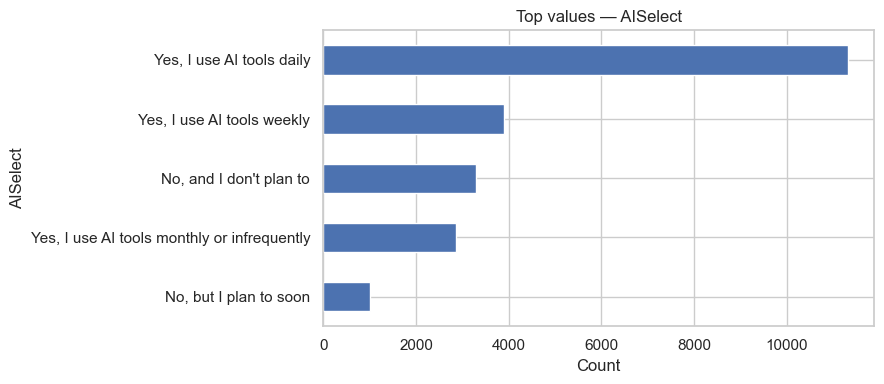

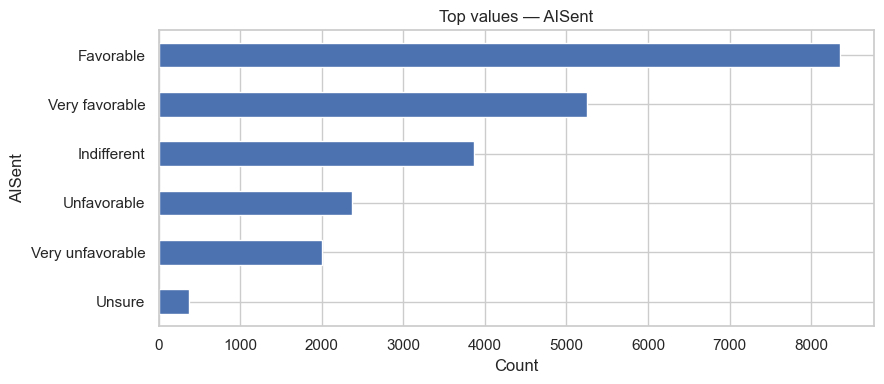

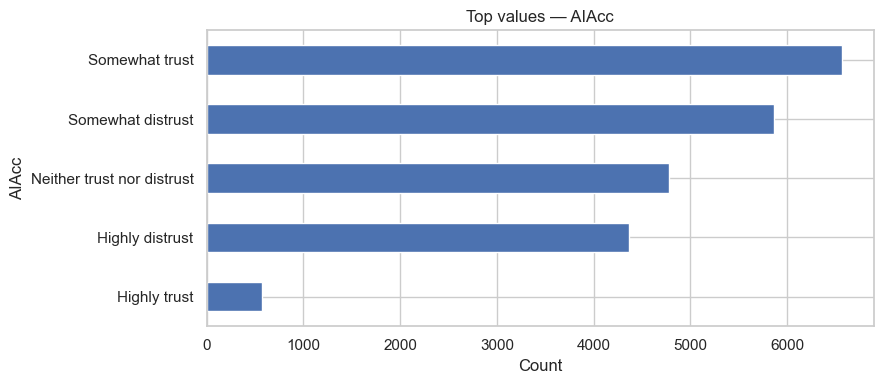

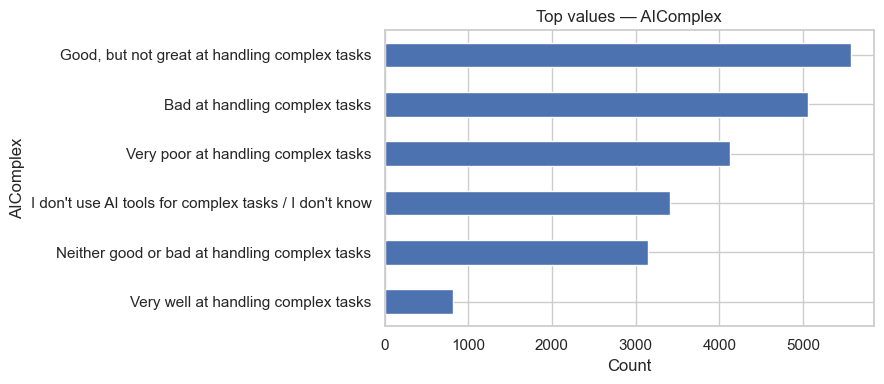

In [168]:

print("AI usage / work-experience columns used for EDA:")
print(ai_usage_cols_eda)

value_count_rows = []
for col in ai_usage_cols_eda:
    vc = data[col].astype(str).replace("nan", np.nan).value_counts(dropna=True).head(10)
    for value, count in vc.items():
        value_count_rows.append({"feature": col, "value": value, "count": count})

ai_usage_value_counts = pd.DataFrame(value_count_rows)
display(ai_usage_value_counts.head(80))


multi_choice_cols_eda = []
for col in ai_usage_cols_eda:
    sample = data[col].dropna().astype(str).head(1000)
    if sample.str.contains(";", regex=False).any():
        multi_choice_cols_eda.append(col)

print("Detected multi-choice AI usage columns:", multi_choice_cols_eda)
for col in multi_choice_cols_eda[:8]:
    top_items = (
        data[col]
        .dropna()
        .astype(str)
        .str.split(";")
        .explode()
        .str.strip()
        .value_counts()
        .head(15)
        .rename_axis(col)
        .reset_index(name="count")
    )
    display(top_items)


plot_ai_cols = [c for c in ["AISelect", "AISent", "AIAcc", "AIComplex", "AIThreat", "AIExplain", "NewRole", "LearnCodeAI"] if c in data.columns]
for col in plot_ai_cols[:4]:
    top = data[col].astype(str).replace("nan", np.nan).value_counts(dropna=True).head(10)
    plt.figure(figsize=(9, 4))
    top.sort_values().plot(kind="barh")
    plt.title(f"Top values — {col}")
    plt.xlabel("Count")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()



Summary for WorkExp:


,WorkExp
count,23362.000000
mean,13.498202
std,10.050854
min,1.000000
25%,5.000000
50%,11.000000
75%,20.000000
max,100.000000


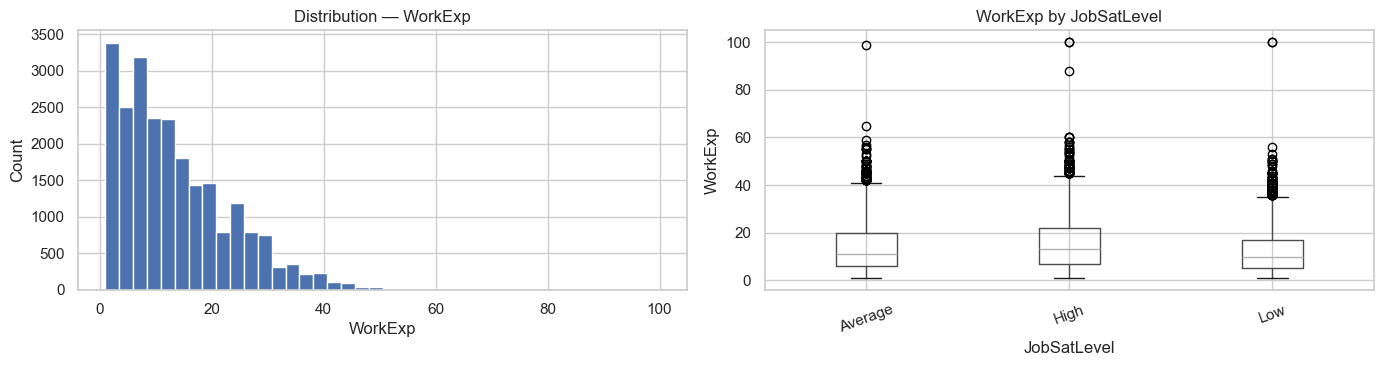

Kruskal-Wallis for WorkExp vs JobSatLevel: statistic=303.8484, p-value=1.0475e-66

Summary for YearsCode:


,YearsCode
count,23740.000000
mean,17.819166
std,11.071262
min,1.000000
25%,9.000000
50%,15.000000
75%,25.000000
max,100.000000


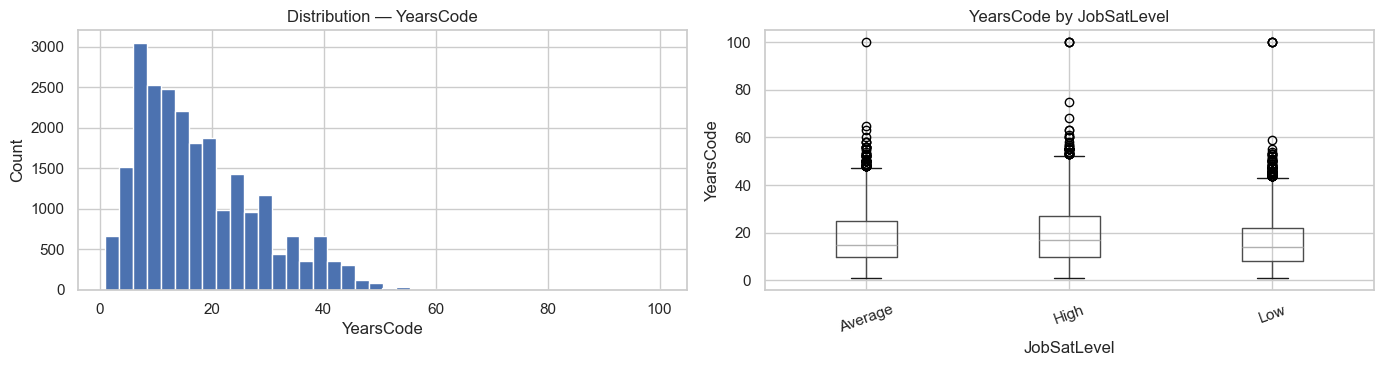

Kruskal-Wallis for YearsCode vs JobSatLevel: statistic=261.3302, p-value=1.7900e-57


In [169]:

numeric_eda_cols = ["WorkExp", "YearsCode"]

for col in numeric_eda_cols:
    print(f"\nSummary for {col}:")
    display(data[[col]].describe())

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].hist(data[col].dropna(), bins=40)
    axes[0].set_title(f"Distribution — {col}")
    axes[0].set_xlabel(col)
    axes[0].set_ylabel("Count")

    data.boxplot(column=col, by=TARGET, ax=axes[1])
    axes[1].set_title(f"{col} by {TARGET}")
    axes[1].set_xlabel(TARGET)
    axes[1].set_ylabel(col)
    axes[1].tick_params(axis="x", rotation=20)
    fig.suptitle("")
    plt.tight_layout()
    plt.show()

    temp = data[[col, TARGET]].dropna()
    groups = [g[col].values for _, g in temp.groupby(TARGET)]
    if len(groups) >= 2:
        stat, p = ss.kruskal(*groups)
        print(f"Kruskal-Wallis for {col} vs {TARGET}: statistic={stat:.4f}, p-value={p:.4e}")


TechEndorse columns: 10
TechOppose columns: 10


,feature,method,score,p_value
0,Currency,Cramér's V + chi-square,0.0773,2.770660e-22
1,Country,Cramér's V + chi-square,0.0766,2.333896e-18
2,TechEndorseIntro,Cramér's V + chi-square,0.0657,3.181160e-43


,feature,method,kruskal_stat,p_value,spearman_to_target
0,CompTotal_USD_EDA,Kruskal + Spearman,232.0162,4.152664e-51,0.1143
16,TechOppose_2,Kruskal + Spearman,19.4760,5.899967e-05,0.0275
1,TechEndorse_1,Kruskal + Spearman,15.4703,4.371766e-04,-0.0259
14,TechOppose_15,Kruskal + Spearman,14.4945,7.121140e-04,0.0259
3,TechEndorse_2,Kruskal + Spearman,13.5780,1.126067e-03,0.0242
20,TechOppose_9,Kruskal + Spearman,10.7598,4.608386e-03,-0.0185
11,TechOppose_1,Kruskal + Spearman,10.7283,4.681501e-03,-0.0176
6,TechEndorse_5,Kruskal + Spearman,10.7254,4.688316e-03,-0.0035
7,TechEndorse_6,Kruskal + Spearman,7.4104,2.459570e-02,0.0172
9,TechEndorse_8,Kruskal + Spearman,6.7002,3.508013e-02,-0.0138


Highly correlated survey pairs (|r| >= 0.7):


,Feature A,Feature B,Spearman r
0,TechEndorse_13,TechOppose_15,0.7943


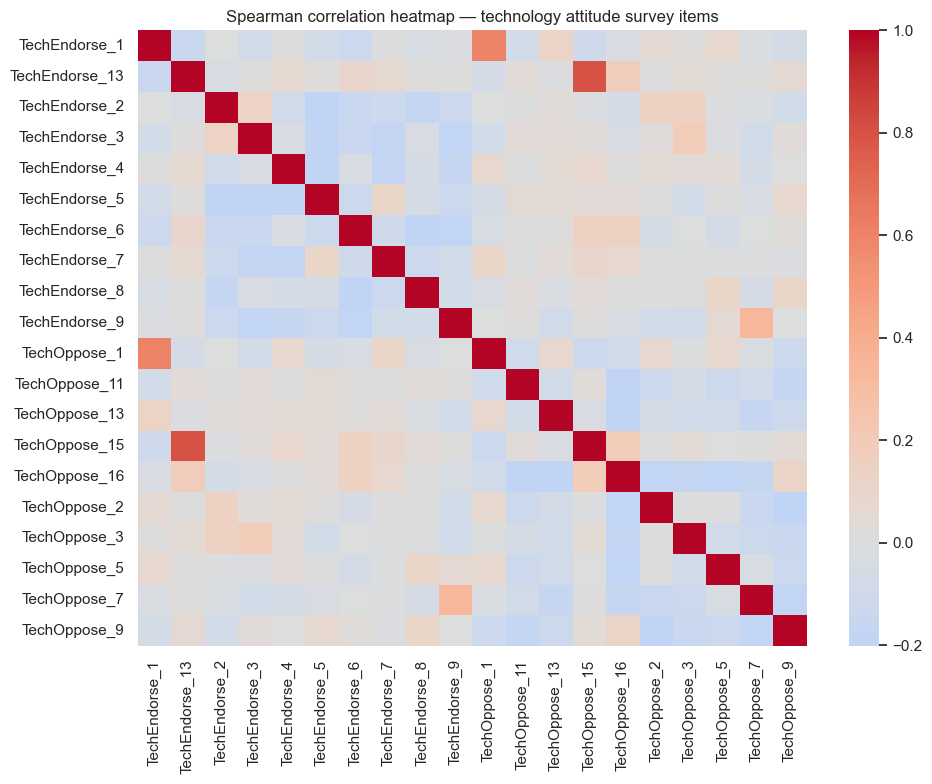

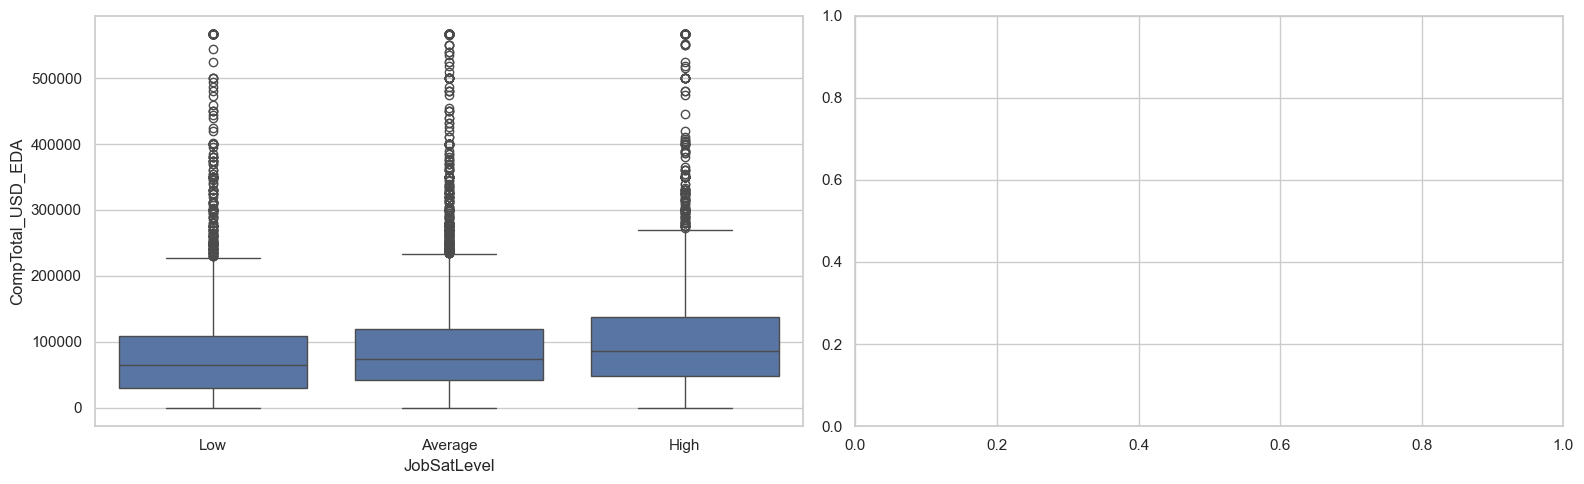

Exploratory PCA components needed for 90% variance: 16 / 20


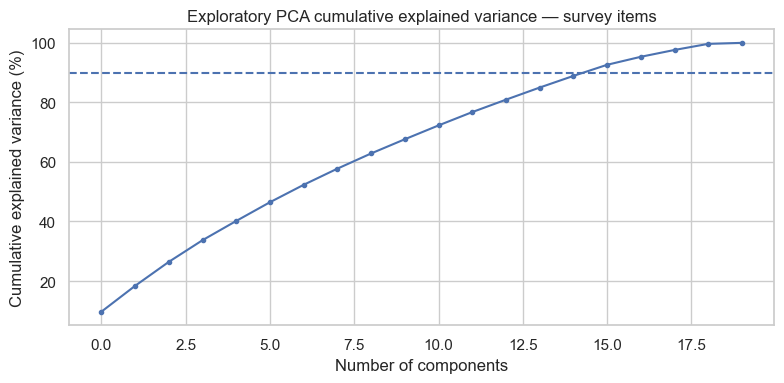

In [170]:

# Restored compensation + technology-attitude EDA: salary conversion, association tests, Spearman correlation, PCA variance
RATES_TO_USD_EDA = {
    "USD": 1.0, "EUR": 1.08, "GBP": 1.25, "INR": 0.012, "CAD": 0.74,
    "AUD": 0.65, "BRL": 0.20, "PLN": 0.25, "SEK": 0.095, "CHF": 1.10,
    "JPY": 0.0066, "CZK": 0.043, "HUF": 0.0028, "MYR": 0.21, "EGP": 0.021,
    "LKR": 0.0033, "RSD": 0.0092, "RON": 0.22, "UYU": 0.026, "AED": 0.27,
    "ARS": 0.0012, "RUB": 0.011, "NOK": 0.092, "CRC": 0.002, "PHP": 0.018,
    "ILS": 0.27, "BGN": 0.55, "MAD": 0.10, "MXN": 0.06, "TRY": 0.031,
    "BOB": 0.14, "NPR": 0.0075, "ZAR": 0.053, "TND": 0.32, "CNY": 0.14,
    "PKR": 0.0036, "SGD": 0.74, "AZN": 0.59, "DKK": 0.14, "NGN": 0.0007,
    "IRR": 0.000024, "HKD": 0.13, "TWD": 0.031, "VND": 0.00004, "CLP": 0.0011,
    "KRW": 0.00074, "COP": 0.00026, "UGX": 0.00026, "JOD": 1.41, "IDR": 0.000063,
    "UAH": 0.025, "BDT": 0.009, "ANG": 0.55, "DOP": 0.017, "GTQ": 0.13,
    "QAR": 0.27, "BAM": 0.55, "AMD": 0.0025, "THB": 0.027, "KZT": 0.0022,
    "GEL": 0.37, "GHS": 0.075, "KES": 0.0075, "NZD": 0.60, "PEN": 0.27,
    "BHD": 2.65, "SAR": 0.27, "OMR": 2.60, "KWD": 3.25, "NON": 1.0,
}

comp_eda = data.copy()
if "Currency" in comp_eda.columns:
    comp_eda["Clean_Currency_EDA"] = comp_eda["Currency"].astype(str).str[:3].str.upper()
    comp_eda["ExchangeRate_EDA"] = comp_eda["Clean_Currency_EDA"].map(RATES_TO_USD_EDA).fillna(1.0)
else:
    comp_eda["ExchangeRate_EDA"] = 1.0

if "CompTotal" in comp_eda.columns:
    comp_eda["CompTotal_USD_EDA"] = pd.to_numeric(comp_eda["CompTotal"], errors="coerce") * comp_eda["ExchangeRate_EDA"]
    q99_eda = comp_eda["CompTotal_USD_EDA"].quantile(0.99)
    comp_eda["CompTotal_USD_EDA"] = comp_eda["CompTotal_USD_EDA"].clip(upper=q99_eda)

endorse_cols_eda = sorted([c for c in data.columns if c.startswith("TechEndorse_") and "_TEXT" not in c])
oppose_cols_eda = sorted([c for c in data.columns if c.startswith("TechOppose_") and "_TEXT" not in c])
survey_cols_eda = endorse_cols_eda + oppose_cols_eda
print(f"TechEndorse columns: {len(endorse_cols_eda)}")
print(f"TechOppose columns: {len(oppose_cols_eda)}")


def cramers_v_eda(x, y):
    ct = pd.crosstab(x, y)
    if ct.size == 0:
        return np.nan
    chi2 = ss.chi2_contingency(ct)[0]
    n = ct.sum().sum()
    r, k = ct.shape
    if n <= 1:
        return np.nan
    phi2corr = max(0, chi2 / n - ((k - 1) * (r - 1)) / (n - 1))
    rcorr = r - ((r - 1) ** 2) / (n - 1)
    kcorr = k - ((k - 1) ** 2) / (n - 1)
    m = min(kcorr - 1, rcorr - 1)
    return 0.0 if m <= 0 else np.sqrt(phi2corr / m)

cat_features_eda = [c for c in ["Currency", "Country", "TechEndorseIntro"] if c in comp_eda.columns]
num_features_eda = [c for c in ["CompTotal_USD_EDA"] if c in comp_eda.columns] + survey_cols_eda

cat_results_eda = []
for col in cat_features_eda:
    temp = comp_eda[[col, TARGET]].dropna()
    if not temp.empty:
        _, p, _, _ = ss.chi2_contingency(pd.crosstab(temp[col].astype(str), temp[TARGET]))
        cat_results_eda.append({"feature": col, "method": "Cramér's V + chi-square", "score": round(cramers_v_eda(temp[col].astype(str), temp[TARGET]), 4), "p_value": p})

def target_ordered_codes(s):
    return s.map(target_mapping)

num_results_eda = []
for col in num_features_eda:
    temp = comp_eda[[col, TARGET]].copy()
    temp[col] = pd.to_numeric(temp[col], errors="coerce")
    temp = temp.dropna()
    if not temp.empty:
        groups = [g[col].values for _, g in temp.groupby(TARGET)]
        if len(groups) >= 2:
            stat, p = ss.kruskal(*groups)
            rho = temp[col].corr(target_ordered_codes(temp[TARGET]), method="spearman")
            num_results_eda.append({"feature": col, "method": "Kruskal + Spearman", "kruskal_stat": round(stat, 4), "p_value": p, "spearman_to_target": round(rho, 4) if pd.notna(rho) else np.nan})

display(pd.DataFrame(cat_results_eda).sort_values("score", ascending=False))
display(pd.DataFrame(num_results_eda).sort_values("kruskal_stat", ascending=False).head(20))

# Spearman correlation heatmap for survey columns
survey_corr_df = comp_eda[survey_cols_eda].replace(-1, np.nan).apply(pd.to_numeric, errors="coerce") if survey_cols_eda else pd.DataFrame()
if survey_corr_df.shape[1] > 1:
    corr_matrix_eda = survey_corr_df.corr(method="spearman")
    high_pairs_eda = []
    upper = corr_matrix_eda.where(np.triu(np.ones(corr_matrix_eda.shape), k=1).astype(bool))
    for c in upper.columns:
        for r in upper.index:
            val = upper.loc[r, c]
            if pd.notna(val) and abs(val) >= 0.7:
                high_pairs_eda.append({"Feature A": r, "Feature B": c, "Spearman r": round(val, 4)})
    print("Highly correlated survey pairs (|r| >= 0.7):")
    display(pd.DataFrame(high_pairs_eda).sort_values("Spearman r", key=abs, ascending=False) if high_pairs_eda else pd.DataFrame(columns=["Feature A", "Feature B", "Spearman r"]))

    plt.figure(figsize=(10, 8))
    sns.heatmap(corr_matrix_eda, cmap="coolwarm", center=0, square=False)
    plt.title("Spearman correlation heatmap — technology attitude survey items")
    plt.tight_layout()
    plt.show()


if "CompTotal_USD_EDA" in comp_eda.columns:
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    sns.boxplot(data=comp_eda, x=TARGET, y="CompTotal_USD_EDA", order=target_order, ax=axes[0])
    plt.tight_layout()
    plt.show()


if survey_corr_df.shape[1] > 1:
    pca_imp_eda = SimpleImputer(strategy="median")
    pca_scale_eda = StandardScaler()
    X_pca_eda = pca_scale_eda.fit_transform(pca_imp_eda.fit_transform(survey_corr_df))
    pca_eda = PCA().fit(X_pca_eda)
    cumvar_eda = np.cumsum(pca_eda.explained_variance_ratio_ * 100)
    print(f"Exploratory PCA components needed for 90% variance: {int(np.argmax(cumvar_eda >= 90)) + 1} / {len(cumvar_eda)}")
    plt.figure(figsize=(8, 4))
    plt.plot(cumvar_eda, marker="o", markersize=3)
    plt.axhline(90, linestyle="--")
    plt.title("Exploratory PCA cumulative explained variance — survey items")
    plt.xlabel("Number of components")
    plt.ylabel("Cumulative explained variance (%)")
    plt.tight_layout()
    plt.show()


Stack Overflow EDA features:
['SOTagsHaveWorkedWith', 'SOTagsWantToWorkWith', 'SOTagsAdmired', 'SOTagsHaveEntry', 'SOTagsWant Entry', 'SOAccount', 'SOVisitFreq', 'SOPartFreq', 'SOComm', 'SOFriction', 'SO_Actions_1', 'SO_Actions_16', 'SO_Actions_3', 'SO_Actions_4', 'SO_Actions_6', 'SO_Actions_7', 'SO_Actions_15', 'SO_Actions_15_TEXT']


,feature,missing_%,unique_values
4,SOTagsWant Entry,99.03,202
3,SOTagsHaveEntry,98.94,223
17,SO_Actions_15_TEXT,97.88,471
2,SOTagsAdmired,64.50,923
1,SOTagsWantToWorkWith,60.74,1678
0,SOTagsHaveWorkedWith,48.45,1442
11,SO_Actions_16,32.27,10
10,SO_Actions_1,26.66,15
12,SO_Actions_3,26.66,15
13,SO_Actions_4,26.66,15


,feature,chi2,p_value,unique_values
8,SOComm,118.1106,1.222788e-20,6
7,SOPartFreq,85.0042,3.303343e-12,8
9,SOFriction,37.2657,1.028344e-05,5
6,SOVisitFreq,44.3451,1.333633e-05,7
5,SOAccount,21.3611,2.685114e-04,3
12,SO_Actions_3,42.7955,3.642193e-02,15
16,SO_Actions_15,40.6798,5.744336e-02,15
15,SO_Actions_7,38.8728,8.299064e-02,15
11,SO_Actions_16,25.3743,1.149481e-01,10
13,SO_Actions_4,35.8474,1.465255e-01,15


,feature,mutual_information
1,SOTagsWantToWorkWith,0.077087
0,SOTagsHaveWorkedWith,0.068446
2,SOTagsAdmired,0.043429
3,SOTagsHaveEntry,0.010644
4,SOTagsWant Entry,0.009579
8,SOComm,0.002508
7,SOPartFreq,0.001874
12,SO_Actions_3,0.001086
6,SOVisitFreq,0.001063
16,SO_Actions_15,0.001052


,feature,rf_importance
1,SOTagsWantToWorkWith,0.111624
0,SOTagsHaveWorkedWith,0.105485
2,SOTagsAdmired,0.087095
8,SOComm,0.075855
7,SOPartFreq,0.067777
12,SO_Actions_3,0.063301
15,SO_Actions_7,0.062493
10,SO_Actions_1,0.061292
14,SO_Actions_6,0.060680
13,SO_Actions_4,0.057636


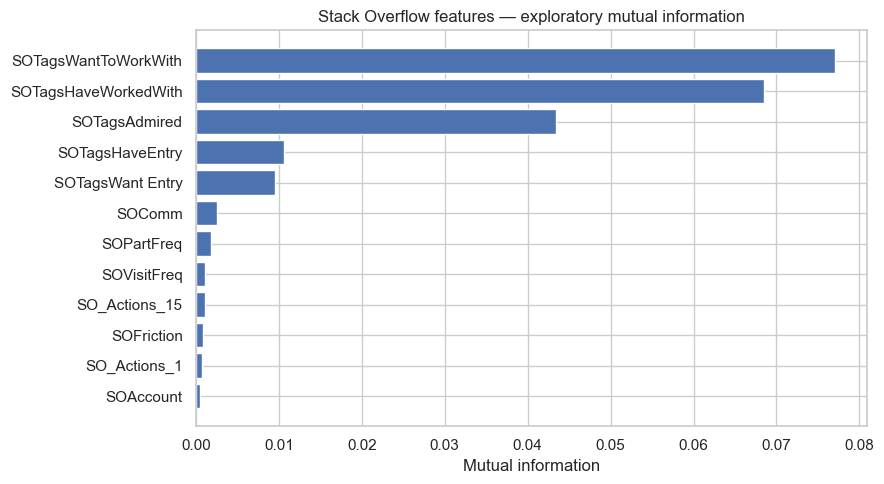

In [171]:


so_features_eda = stackoverflow_cols_eda
print("Stack Overflow EDA features:")
print(so_features_eda)

so_summary = pd.DataFrame({
    "feature": so_features_eda,
    "missing_%": [round(data[c].isna().mean() * 100, 2) for c in so_features_eda],
    "unique_values": [data[c].nunique(dropna=True) for c in so_features_eda],
}).sort_values(["missing_%", "unique_values"], ascending=[False, False])
display(so_summary)

chi_rows = []
for col in so_features_eda:
    temp = data[[col, TARGET]].dropna()
    if temp.empty or temp[col].nunique() < 2:
        continue
    table = pd.crosstab(temp[col].astype(str), temp[TARGET])
    if table.shape[0] > 1 and table.shape[1] > 1:
        chi2_stat, p, _, _ = ss.chi2_contingency(table)
        chi_rows.append({"feature": col, "chi2": round(chi2_stat, 4), "p_value": p, "unique_values": temp[col].nunique()})

so_chi_df = pd.DataFrame(chi_rows).sort_values("p_value") if chi_rows else pd.DataFrame()
display(so_chi_df)


so_model_features = [c for c in so_features_eda if c in data.columns and c != "SO_Actions_15_TEXT"]
if so_model_features:
    so_tmp = data[so_model_features + [TARGET]].copy()
    for col in so_model_features:
        so_tmp[col] = so_tmp[col].fillna("Missing").astype(str)
        
        le = LabelEncoder()
        so_tmp[col] = le.fit_transform(so_tmp[col])
    y_so = so_tmp[TARGET]
    X_so = so_tmp[so_model_features]
    mi = mutual_info_classif(X_so, y_so, discrete_features=True, random_state=RANDOM_STATE)
    so_mi_df = pd.DataFrame({"feature": so_model_features, "mutual_information": mi}).sort_values("mutual_information", ascending=False)
    display(so_mi_df)

    rf_eda = RandomForestClassifier(n_estimators=80, max_depth=8, random_state=RANDOM_STATE, n_jobs=-1, class_weight="balanced")
    rf_eda.fit(X_so, y_so)
    so_rf_df = pd.DataFrame({"feature": so_model_features, "rf_importance": rf_eda.feature_importances_}).sort_values("rf_importance", ascending=False)
    display(so_rf_df)

    merged_so_importance = so_mi_df.merge(so_rf_df, on="feature", how="outer")
    plot_so = merged_so_importance.head(12).sort_values("mutual_information")
    plt.figure(figsize=(9, 5))
    plt.barh(plot_so["feature"], plot_so["mutual_information"])
    plt.title("Stack Overflow features — exploratory mutual information")
    plt.xlabel("Mutual information")
    plt.tight_layout()
    plt.show()


Tools/platforms/environment columns:
['ToolCountWork', 'ToolCountPersonal', 'WebframeChoice', 'WebframeHaveWorkedWith', 'WebframeWantToWorkWith', 'WebframeAdmired', 'WebframeHaveEntry', 'WebframeWantEntry', 'DevEnvsChoice', 'DevEnvsHaveWorkedWith', 'DevEnvsWantToWorkWith', 'DevEnvsAdmired', 'OpSysPersonal use', 'OpSysProfessional use', 'CommPlatformHaveWorkedWith', 'CommPlatformWantToWorkWith', 'CommPlatformAdmired', 'CommPlatformHaveEntr', 'CommPlatformWantEntr', 'PurchaseInfluence', 'EmploymentAddl', 'Industry', 'AgentUsesGeneral']


,feature,missing_%,unique_values
18,CommPlatformWantEntr,97.07,349
17,CommPlatformHaveEntr,96.31,416
7,WebframeWantEntry,92.47,981
6,WebframeHaveEntry,90.37,1231
22,AgentUsesGeneral,83.96,139
5,WebframeAdmired,52.31,2523
4,WebframeWantToWorkWith,46.76,4388
11,DevEnvsAdmired,43.25,3067
10,DevEnvsWantToWorkWith,40.12,4105
16,CommPlatformAdmired,35.62,3310


Detected multi-choice tools/platforms columns: ['WebframeHaveWorkedWith', 'WebframeWantToWorkWith', 'WebframeAdmired', 'WebframeHaveEntry', 'WebframeWantEntry', 'DevEnvsHaveWorkedWith', 'DevEnvsWantToWorkWith', 'DevEnvsAdmired', 'OpSysPersonal use', 'OpSysProfessional use', 'CommPlatformHaveWorkedWith', 'CommPlatformWantToWorkWith', 'CommPlatformAdmired', 'EmploymentAddl', 'AgentUsesGeneral']


,WebframeHaveWorkedWith,count
0,Node.js,8249
1,React,7838
2,jQuery,4096
3,Next.js,3629
4,ASP.NET Core,3590
5,Express,3416
6,Angular,3291
7,Vue.js,3121
8,Spring Boot,2599
9,ASP.NET,2531


,WebframeWantToWorkWith,count
0,React,5141
1,Node.js,4842
2,Vue.js,2595
3,ASP.NET Core,2577
4,Next.js,2444
5,Angular,2104
6,FastAPI,2040
7,Express,1874
8,Spring Boot,1842
9,Svelte,1748


,WebframeAdmired,count
0,Node.js,4323
1,React,4110
2,ASP.NET Core,2226
3,Next.js,1626
4,Vue.js,1601
5,Express,1552
6,Angular,1497
7,Spring Boot,1410
8,FastAPI,1388
9,jQuery,1235


... (5 outputs left out)

,OpSysPersonal use,count
0,Windows,11885
1,MacOS,7428
2,Android,5945
3,Ubuntu,5904
4,iOS,4032
5,Linux (non-WSL),3544
6,Windows Subsystem for Linux (WSL),3299
7,Debian,2213
8,Arch,1841
9,iPadOS,1677


,OpSysProfessional use,count
0,Windows,10393
1,MacOS,7747
2,Ubuntu,6076
3,Windows Subsystem for Linux (WSL),3757
4,Linux (non-WSL),3508
5,Android,2556
6,iOS,2362
7,Debian,2171
8,Red Hat,1113
9,Arch,791



PurchaseInfluence distribution by JobSatLevel:


JobSatLevel,Low,Average,High
PurchaseInfluence,,,
Missing,0.481636,0.336394,0.181970
No,0.304561,0.470608,0.224831
"Yes, I endorsed a tool that was open-source and is currently used by more than just myself but no purchase was made",0.246711,0.521107,0.232182
"Yes, I endorsed a tool that was ultimately not purchased or used at my organization",0.367470,0.454217,0.178313
"Yes, I influenced the purchase of a substantial addition to the tech stack",0.209150,0.456863,0.333987
"Yes, I influenced the purchase of a tool that more than five colleagues use but it is not a substantial addition to the tech stack",0.245283,0.509973,0.244744


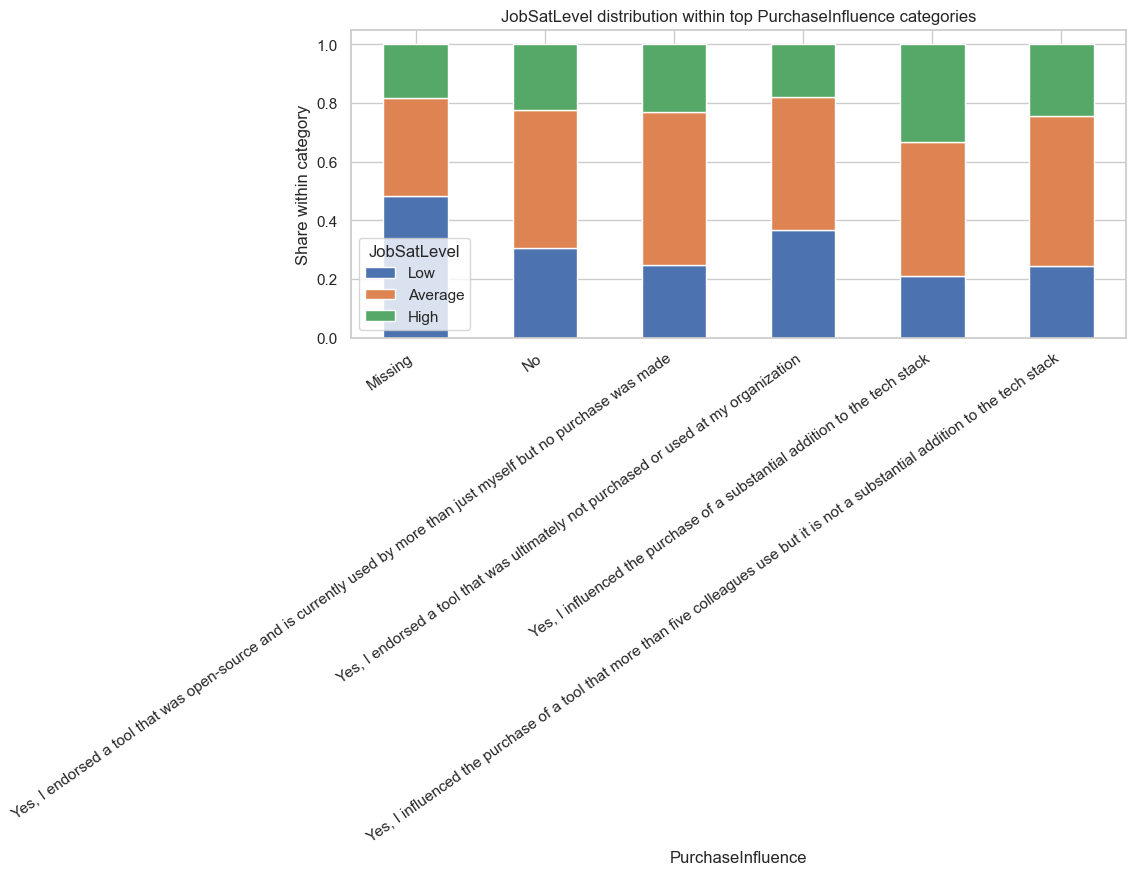


Industry distribution by JobSatLevel:


JobSatLevel,Low,Average,High
Industry,,,
Banking/Financial Services,0.294243,0.478678,0.227079
Computer Systems Design and Services,0.211881,0.491089,0.297030
Energy,0.220807,0.501062,0.278132
Fintech,0.281452,0.463710,0.254839
Government,0.300142,0.475107,0.224751
Healthcare,0.288462,0.459402,0.252137
Higher Education,0.237327,0.500000,0.262673
Insurance,0.344937,0.481013,0.174051
"Internet, Telecomm or Information Services",0.284351,0.481870,0.233779


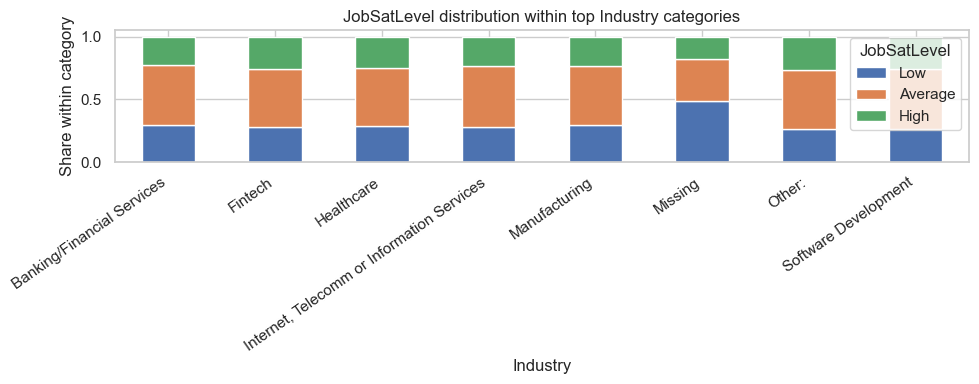


AgentUsesGeneral distribution by JobSatLevel:


JobSatLevel,Low,Average,High
AgentUsesGeneral,,,
Agent/multi-agent orchestration,0.280488,0.414634,0.304878
Agent/multi-agent orchestration;Integration with external agents and APIs,0.296875,0.515625,0.187500
Agent/multi-agent orchestration;Integration with external agents and APIs;Personalized agent creation,0.083333,0.666667,0.250000
Agent/multi-agent orchestration;MCP servers,0.234375,0.531250,0.234375
Agent/multi-agent orchestration;MCP servers;Integration with external agents and APIs,0.166667,0.545455,0.287879
Agent/multi-agent orchestration;MCP servers;Integration with external agents and APIs;Personalized agent creation,0.117647,0.647059,0.235294
Agent/multi-agent orchestration;MCP servers;Other specific task (write in):,0.000000,1.000000,0.000000
Agent/multi-agent orchestration;MCP servers;Personalized agent creation,0.166667,0.333333,0.500000
Agent/multi-agent orchestration;Other specific task (write in):,0.000000,1.000000,0.000000


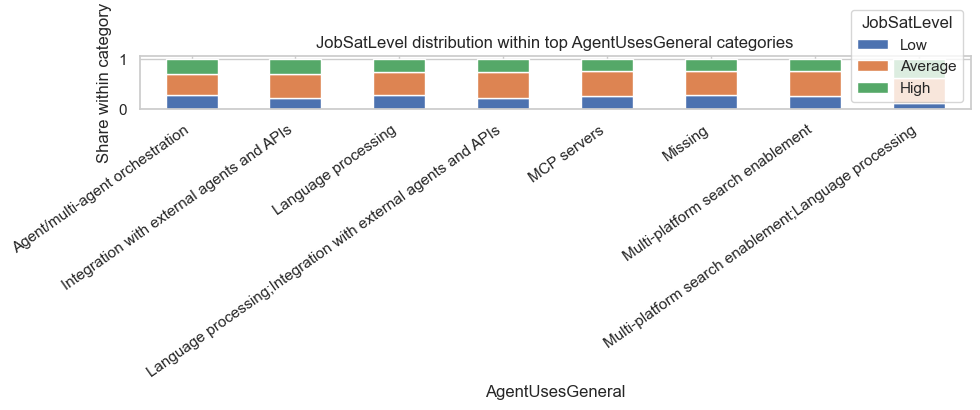

In [172]:


tools_cols_eda = tools_platform_cols_eda
print("Tools/platforms/environment columns:")
print(tools_cols_eda)

tools_summary = pd.DataFrame({
    "feature": tools_cols_eda,
    "missing_%": [round(data[c].isna().mean() * 100, 2) for c in tools_cols_eda],
    "unique_values": [data[c].nunique(dropna=True) for c in tools_cols_eda],
}).sort_values(["missing_%", "unique_values"], ascending=[False, False])
display(tools_summary)

# Original notebooks repeatedly inspected top selections in semicolon-separated tech columns.
tech_multi_cols_eda = []
for col in tools_cols_eda:
    sample = data[col].dropna().astype(str).head(1000)
    if sample.str.contains(";", regex=False).any():
        tech_multi_cols_eda.append(col)

print("Detected multi-choice tools/platforms columns:", tech_multi_cols_eda)
for col in tech_multi_cols_eda[:10]:
    top_items = (
        data[col]
        .dropna()
        .astype(str)
        .str.split(";")
        .explode()
        .str.strip()
        .value_counts()
        .head(15)
        .rename_axis(col)
        .reset_index(name="count")
    )
    display(top_items)

# Compact categorical distributions by target
for col in ["PurchaseInfluence", "Industry", "AgentUsesGeneral"]:
    if col in data.columns:
        print(f"\n{col} distribution by {TARGET}:")
        ct = pd.crosstab(data[col].fillna("Missing"), data[TARGET], normalize="index").reindex(columns=target_order)
        display(ct.head(20))
        top_categories = data[col].fillna("Missing").value_counts().head(8).index
        ct_plot = ct.loc[ct.index.intersection(top_categories)]
        if not ct_plot.empty:
            ct_plot.plot(kind="bar", stacked=True, figsize=(10, 4))
            plt.title(f"{TARGET} distribution within top {col} categories")
            plt.xlabel(col)
            plt.ylabel("Share within category")
            plt.xticks(rotation=35, ha="right")
            plt.tight_layout()
            plt.show()


## Global 80/20 train/test split

In [173]:
train_global, test_global = train_test_split(
    data,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=data[TARGET]
)

train_global = train_global.reset_index(drop=True)
test_global = test_global.reset_index(drop=True)

y_train = train_global[TARGET].copy().reset_index(drop=True)
y_test = test_global[TARGET].copy().reset_index(drop=True)
y_train_encoded = y_train.map(target_mapping).astype(int)
y_test_encoded = y_test.map(target_mapping).astype(int)

print("Train shape:", train_global.shape)
print("Test shape:", test_global.shape)
print("Train target distribution:")
print(y_train.value_counts().reindex(target_order))
print("Test target distribution:")
print(y_test.value_counts().reindex(target_order))

Train shape: (19168, 156)
Test shape: (4793, 156)
Train target distribution:
JobSatLevel
Low        5442
Average    9037
High       4689
Name: count, dtype: int64
Test target distribution:
JobSatLevel
Low        1361
Average    2259
High       1173
Name: count, dtype: int64


In [174]:

cols_to_drop_high_missing = [
    c for c in train_global.columns
    if c != TARGET and train_global[c].isnull().mean() >= 0.70
]

print("Columns dropped because >=70% missing in TRAIN:", cols_to_drop_high_missing)
train_global = train_global.drop(columns=cols_to_drop_high_missing)
test_global = test_global.drop(columns=cols_to_drop_high_missing, errors="ignore")

train_global[TARGET] = y_train.values
test_global[TARGET] = y_test.values

print("Train shape after high-missing column drop:", train_global.shape)
print("Test shape after high-missing column drop:", test_global.shape)

Columns dropped because >=70% missing in TRAIN: ['TechEndorse_13_TEXT', 'TechOppose_15_TEXT', 'LanguagesHaveEntry', 'LanguagesWantEntry', 'DatabaseHaveEntry', 'DatabaseWantEntry', 'PlatformHaveEntry', 'PlatformWantEntry', 'WebframeHaveEntry', 'WebframeWantEntry', 'DevEnvHaveEntry', 'DevEnvWantEntry', 'SOTagsHaveEntry', 'SOTagsWant Entry', 'OfficeStackHaveEntry', 'OfficeStackWantEntry', 'CommPlatformHaveEntr', 'CommPlatformWantEntr', 'AIModelsHaveEntry', 'AIModelsWantEntry', 'SO_Actions_15_TEXT', 'AgentUsesGeneral', 'AIAgentImpactSomewhat agree', 'AIAgentImpactNeutral', 'AIAgentImpactSomewhat disagree', 'AIAgentImpactStrongly agree', 'AIAgentImpactStrongly disagree', 'AIAgentChallengesStrongly disagree', 'AIAgentKnowledge', 'AIAgentKnowWrite', 'AIAgentOrchestration', 'AIAgentOrchWrite', 'AIAgentObserveSecure', 'AIAgentObsWrite', 'AIAgentExternal', 'AIAgentExtWrite']
Train shape after high-missing column drop: (19168, 120)
Test shape after high-missing column drop: (4793, 120)


## Helper functions

In [175]:
def make_unique_columns(df):
    seen = {}
    new_cols = []
    for col in df.columns:
        if col not in seen:
            seen[col] = 0
            new_cols.append(col)
        else:
            seen[col] += 1
            new_cols.append(f"{col}__dup{seen[col]}")
    df = df.copy()
    df.columns = new_cols
    return df



def align_test_to_train(X_train, X_test):
    return X_test.reindex(columns=X_train.columns, fill_value=0)


def split_multi_values(series):
    return series.fillna("").astype(str).apply(lambda x: [item.strip() for item in x.split(";") if item.strip()])


def multi_hot_train_test(train_df, test_df, cols, sep="__"):
    train_df = train_df.copy()
    test_df = test_df.copy()
    fitted = {}
    for col in cols:
        if col not in train_df.columns:
            continue
        train_lists = split_multi_values(train_df[col])
        test_lists = split_multi_values(test_df[col])
        mlb = MultiLabelBinarizer()
        train_encoded = mlb.fit_transform(train_lists)
        test_encoded = mlb.transform(test_lists)
        encoded_cols = [f"{col}{sep}{cls}" for cls in mlb.classes_]
        train_encoded_df = pd.DataFrame(train_encoded, columns=encoded_cols, index=train_df.index)
        test_encoded_df = pd.DataFrame(test_encoded, columns=encoded_cols, index=test_df.index)
        train_df = pd.concat([train_df.drop(columns=[col]), train_encoded_df], axis=1)
        test_df = pd.concat([test_df.drop(columns=[col]), test_encoded_df], axis=1)
        fitted[col] = mlb
    return train_df, test_df, fitted


def simple_ohe_train_test(train_df, test_df, cat_cols):
    cat_cols = [c for c in cat_cols if c in train_df.columns]
    if not cat_cols:
        return train_df.copy(), test_df.copy(), None
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    train_ohe = pd.DataFrame(
        encoder.fit_transform(train_df[cat_cols].astype(str)),
        columns=encoder.get_feature_names_out(cat_cols),
        index=train_df.index,
    )
    test_ohe = pd.DataFrame(
        encoder.transform(test_df[cat_cols].astype(str)),
        columns=encoder.get_feature_names_out(cat_cols),
        index=test_df.index,
    )
    train_out = pd.concat([train_df.drop(columns=cat_cols), train_ohe], axis=1)
    test_out = pd.concat([test_df.drop(columns=cat_cols), test_ohe], axis=1)
    return train_out, test_out, encoder

# AI Usage + Work Experience Features

In [176]:
def preprocess_main_ai_block(train_global, test_global):
    add_cols = ["WorkExp", "NewRole", "LearnCodeAI", "LearnCode"]
    selected_cols = [c for c in first_21_ai_cols + add_cols + [TARGET] if c in train_global.columns]

    train_df = train_global[selected_cols].copy()
    test_df = test_global.reindex(columns=selected_cols).copy()
    test_df[TARGET] = y_test.values

    print("Main AI block raw shape:", train_df.shape, test_df.shape)
    print("Columns:", selected_cols)

    if "WorkExp" in train_df.columns:
        workexp_median = train_df["WorkExp"].median()
        preprocessing_objects["main_ai_workexp_median"] = workexp_median
        train_df["WorkExp"] = train_df["WorkExp"].fillna(workexp_median)
        test_df["WorkExp"] = test_df["WorkExp"].fillna(workexp_median)
        print("WorkExp median from train:", workexp_median)
        print("Train rows with WorkExp > 45 before clipping:", (train_df["WorkExp"] > 45).sum())
        train_df["WorkExp"] = train_df["WorkExp"].clip(upper=45)
        test_df["WorkExp"] = test_df["WorkExp"].clip(upper=45)

        f_score, p_value = f_classif(train_df[["WorkExp"]], train_df[TARGET])
        print(f"WorkExp ANOVA F-score: {f_score[0]:.4f}")
        print(f"WorkExp p-value: {p_value[0]:.4f}")

    mul_choice = [
        "AILearnHow", "AIModelsHaveWorkedWith", "AIModelsWantToWorkWith", "AIModelsAdmired",
        "AIToolCurrently partially AI", "AIToolDon't plan to use AI for this task",
        "AIToolPlan to partially use AI", "AIToolPlan to mostly use AI", "AIToolCurrently mostly AI",
        "AIFrustration", "LearnCode"
    ]
    mul_choice = [c for c in mul_choice if c in train_df.columns]

    # Fill normal categorical columns using train modes
    for c in train_df.columns:
        if c not in mul_choice and c != TARGET and train_df[c].dtype == "object":
            mode_value = train_df[c].mode(dropna=True)
            fill_value = mode_value.iloc[0] if not mode_value.empty else "Unknown"
            train_df[c] = train_df[c].fillna(fill_value)
            test_df[c] = test_df[c].fillna(fill_value)

    if "AIExplain" in train_df.columns:
        def simplify_aiexplain(x):
            x = str(x).lower()
            if "yes" in x:
                return "yes"
            if "no" in x:
                return "no"
            return "other"
        train_df["AIExplain"] = train_df["AIExplain"].apply(simplify_aiexplain)
        test_df["AIExplain"] = test_df["AIExplain"].apply(simplify_aiexplain)

    
    train_df, test_df, mlbs = multi_hot_train_test(train_df, test_df, mul_choice, sep = ";")
    preprocessing_objects["main_ai_mlbs"] = mlbs

    
    cat_cols = [c for c in train_df.select_dtypes(include="object").columns if c != TARGET]
    train_df_ohe, test_df_ohe, encoder = simple_ohe_train_test(train_df.drop(columns=[TARGET]), test_df.drop(columns=[TARGET]), cat_cols)
    preprocessing_objects["main_ai_ohe"] = encoder

    train_df_ohe = train_df_ohe.apply(pd.to_numeric, errors="coerce").fillna(0)
    test_df_ohe = test_df_ohe.reindex(columns=train_df_ohe.columns, fill_value=0).apply(pd.to_numeric, errors="coerce").fillna(0)

    y_mi = y_train_encoded
    mi_scores = mutual_info_classif(train_df_ohe, y_mi, random_state=RANDOM_STATE, discrete_features="auto")
    mi_results = pd.Series(mi_scores, index=train_df_ohe.columns).sort_values(ascending=False)
    print("Top main AI features by MI:")
    print(mi_results.head(10))

    top_cols = mi_results.head(10).index.tolist()
    if "WorkExp" in train_df_ohe.columns and "WorkExp" not in top_cols:
        top_cols.append("WorkExp")

    X_train_main_ai = train_df_ohe[top_cols].copy()
    X_test_main_ai = test_df_ohe[top_cols].copy()

    return X_train_main_ai, X_test_main_ai, mi_results

X_train_main_ai, X_test_main_ai, mi_main_ai = preprocess_main_ai_block(train_global, test_global)
print("Main AI final:", X_train_main_ai.shape, X_test_main_ai.shape)

Main AI block raw shape: (19168, 24) (4793, 24)
Columns: ['AILearnHow', 'AIThreat', 'AIModelsChoice', 'AIModelsHaveWorkedWith', 'AIModelsWantToWorkWith', 'AIModelsAdmired', 'AISelect', 'AISent', 'AIAcc', 'AIComplex', 'AIToolCurrently partially AI', "AIToolDon't plan to use AI for this task", 'AIToolPlan to partially use AI', 'AIToolPlan to mostly use AI', 'AIToolCurrently mostly AI', 'AIFrustration', 'AIExplain', 'AIAgents', 'AIAgentChange', 'WorkExp', 'NewRole', 'LearnCodeAI', 'LearnCode', 'JobSatLevel']
WorkExp median from train: 11.0
Train rows with WorkExp > 45 before clipping: 94
WorkExp ANOVA F-score: 122.0156
WorkExp p-value: 0.0000
Top main AI features by MI:
NewRole_I have neither consider or transitioned into a new career or industry          0.042557
NewRole_I have strongly considered changing my career and/or the industry I work in    0.022658
NewRole_I have somewhat considered changing my career and/or the industry I work in    0.021518
AIThreat_No                         

In [177]:
def preprocess_ai_agent_block(train_global, test_global):
    ai_cols = [
        "AIAgent_Uses", "AIAgentImpactSomewhat agree", "AIAgentImpactNeutral",
        "AIAgentImpactSomewhat disagree", "AIAgentImpactStrongly agree",
        "AIAgentImpactStrongly disagree", "AIAgentChallengesNeutral",
        "AIAgentChallengesSomewhat disagree", "AIAgentChallengesStrongly agree",
        "AIAgentChallengesSomewhat agree", "AIAgentChallengesStrongly disagree",
        "AIAgentKnowledge", "AIAgentKnowWrite", "AIAgentOrchestration",
        "AIAgentOrchWrite", "AIAgentObserveSecure", "AIAgentObsWrite",
        "AIAgentExternal", "AIAgentExtWrite", "AIHuman", "AIOpen", "ICorPM",
        "YearsCode", "DevType", "OrgSize", TARGET
    ]
    cols = [c for c in ai_cols if c in train_global.columns]
    train = train_global[cols].copy()
    test = test_global.reindex(columns=cols).copy()
    test[TARGET] = y_test.values

    agree_score = {
        "AIAgentChallengesStrongly disagree": 1,
        "AIAgentChallengesSomewhat disagree": 2,
        "AIAgentChallengesNeutral": 3,
        "AIAgentChallengesSomewhat agree": 4,
        "AIAgentChallengesStrongly agree": 5,
    }

    def process_challenge_row(row):
        new_row = {}
        for col, score in agree_score.items():
            value = row.get(col)
            if pd.isna(value):
                continue
            for challenge in [c.strip() for c in str(value).split(";") if c.strip()]:
                new_row[challenge] = max(new_row.get(challenge, 0), score)
        return new_row

    train_pivot = pd.DataFrame(train.apply(process_challenge_row, axis=1).tolist()).reset_index(drop=True)
    test_pivot = pd.DataFrame(test.apply(process_challenge_row, axis=1).tolist()).reset_index(drop=True)
    pivot_cols = train_pivot.columns.tolist()
    test_pivot = test_pivot.reindex(columns=pivot_cols)

    challenge_cols = [
        "Integrating AI agents with my existing tools and workflows can be difficult.",
        "My company's IT and/or InfoSec teams have strict rules that do not allow me to use AI agent tools or platforms",
        "I am concerned about the accuracy of the information provided by AI agents.",
        "It takes significant time and effort to learn how to use AI agents effectively.",
        "The cost of using certain AI agent platforms is a barrier.",
        "I have concerns about the security and privacy of data when using AI agents.",
    ]
    orig_challenge_cols = list(agree_score.keys())
    train = train.drop(columns=orig_challenge_cols, errors="ignore").reset_index(drop=True)
    test = test.drop(columns=orig_challenge_cols, errors="ignore").reset_index(drop=True)
    existing_challenge_cols = [c for c in challenge_cols if c in train_pivot.columns]
    train = pd.concat([train, train_pivot[existing_challenge_cols].reset_index(drop=True)], axis=1)
    test = pd.concat([test, test_pivot[existing_challenge_cols].reset_index(drop=True)], axis=1)
    train[existing_challenge_cols] = train[existing_challenge_cols].fillna(3)
    test[existing_challenge_cols] = test[existing_challenge_cols].fillna(3)
    train["AI_Challenges_Total"] = train[existing_challenge_cols].sum(axis=1) if existing_challenge_cols else 0
    test["AI_Challenges_Total"] = test[existing_challenge_cols].sum(axis=1) if existing_challenge_cols else 0

    if "AIAgent_Uses" in train.columns:
        def count_uses(x):
            x = str(x).strip()
            if x in ("", "nan", "None"):
                return 0
            return x.count(";") + 1
        train["AIAgent_Uses_Count"] = train["AIAgent_Uses"].apply(count_uses)
        test["AIAgent_Uses_Count"] = test["AIAgent_Uses"].apply(count_uses)
        train = train.drop(columns=["AIAgent_Uses"], errors="ignore")
        test = test.drop(columns=["AIAgent_Uses"], errors="ignore")

    if "AIHuman" in train.columns:
        train_h = train["AIHuman"].fillna("").astype(str).str.get_dummies(sep=";")
        train_h.columns = ["AIHuman_" + c.strip().replace(" ", "_") for c in train_h.columns]
        test_h = test["AIHuman"].fillna("").astype(str).str.get_dummies(sep=";")
        test_h.columns = ["AIHuman_" + c.strip().replace(" ", "_") for c in test_h.columns]
        test_h = test_h.reindex(columns=train_h.columns, fill_value=0)
        train = pd.concat([train.drop(columns=["AIHuman"], errors="ignore").reset_index(drop=True), train_h.reset_index(drop=True)], axis=1)
        test = pd.concat([test.drop(columns=["AIHuman"], errors="ignore").reset_index(drop=True), test_h.reset_index(drop=True)], axis=1)

    if "YearsCode" in train.columns:
        train["YearsCode"] = pd.to_numeric(train["YearsCode"], errors="coerce")
        test["YearsCode"] = pd.to_numeric(test["YearsCode"], errors="coerce")
        years_median = train["YearsCode"].median()
        train["YearsCode"] = train["YearsCode"].fillna(years_median)
        test["YearsCode"] = test["YearsCode"].fillna(years_median)
        q1, q3 = train["YearsCode"].quantile([0.25, 0.75])
        iqr = q3 - q1
        lb, ub = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        train["YearsCode"] = train["YearsCode"].clip(lb, ub)
        test["YearsCode"] = test["YearsCode"].clip(lb, ub)

    if "OrgSize" in train.columns:
        org_map = {
            "Just me - I am a freelancer, sole proprietor, etc.": 0,
            "Less than 20 employees": 1,
            "20 to 99 employees": 2,
            "100 to 499 employees": 3,
            "500 to 999 employees": 4,
            "1,000 to 4,999 employees": 5,
            "5,000 to 9,999 employees": 6,
            "10,000 or more employees": 7,
            "Unknown": 8,
            "I don't know": 8,
        }
        train["OrgSize"] = train["OrgSize"].fillna("Unknown").map(org_map).fillna(8)
        test["OrgSize"] = test["OrgSize"].fillna("Unknown").map(org_map).fillna(8)

    if "DevType" in train.columns:
        def group_dev_type(dev_type):
            if pd.isna(dev_type):
                return "Unknown"
            dev_type = str(dev_type)
            if any(k in dev_type for k in ["back-end", "front-end", "full-stack", "mobile", "desktop", "embedded", "game", "Architect", "QA"]):
                return "Software Engineering"
            if any(k in dev_type for k in ["Data scientist", "Data engineer", "AI/ML", "AI apps", "Applied scientist", "Data or business analyst"]):
                return "Data & AI"
            if any(k in dev_type for k in ["Cloud", "DevOps", "System administrator", "Database", "Cybersecurity", "Support"]):
                return "Infrastructure & Ops"
            if any(k in dev_type for k in ["manager", "executive", "Founder", "VP", "Product"]):
                return "Leadership & Product"
            return "Other"

        train["DevType_Grouped"] = train["DevType"].apply(group_dev_type)
        test["DevType_Grouped"] = test["DevType"].apply(group_dev_type)

        jobsat_map_local = {"Low": 1, "Average": 2, "High": 3}
        dev_mean = train.assign(_target_num=train[TARGET].map(jobsat_map_local)).groupby("DevType")["_target_num"].mean()
        global_dev_mean = train[TARGET].map(jobsat_map_local).mean()
        train["DevType_encoded"] = train["DevType"].map(dev_mean).fillna(global_dev_mean)
        test["DevType_encoded"] = test["DevType"].map(dev_mean).fillna(global_dev_mean)
        train = train.drop(columns=["DevType", "AIOpen"], errors="ignore")
        test = test.drop(columns=["DevType", "AIOpen"], errors="ignore")

    if "ICorPM" in train.columns:
        train["ICorPM"] = train["ICorPM"].fillna("Unknown").astype(str)
        test["ICorPM"] = test["ICorPM"].fillna("Unknown").astype(str)
        train_classes = sorted(train["ICorPM"].unique().tolist() + ["Unknown"])
        icorpm_map = {v: i for i, v in enumerate(train_classes)}
        train["ICorPM"] = train["ICorPM"].map(icorpm_map).fillna(icorpm_map["Unknown"])
        test["ICorPM"] = test["ICorPM"].apply(lambda x: x if x in icorpm_map else "Unknown").map(icorpm_map)
        preprocessing_objects["ai_agent_icorpm_map"] = icorpm_map

    train[TARGET] = train[TARGET].map({"Low": 1, "Average": 2, "High": 3})
    test[TARGET] = test[TARGET].map({"Low": 1, "Average": 2, "High": 3})

    y_train_block = train[TARGET].astype(int)
    X_train_full = train.drop(columns=[TARGET]).apply(pd.to_numeric, errors="coerce").fillna(0)
    X_test_full = test.drop(columns=[TARGET]).reindex(columns=X_train_full.columns, fill_value=0).apply(pd.to_numeric, errors="coerce").fillna(0)

    discrete_mask = [X_train_full[c].nunique() < 20 for c in X_train_full.columns]
    mi_scores = mutual_info_classif(X_train_full, y_train_block, discrete_features=discrete_mask, random_state=RANDOM_STATE)
    mi_df = pd.DataFrame({"Feature": X_train_full.columns, "MI Score": mi_scores}).sort_values("MI Score", ascending=False).reset_index(drop=True)
    top_features = mi_df.head(5)["Feature"].tolist()
    print("Top AI-agent features:", top_features)
    preprocessing_objects["ai_agent_top5_features"] = top_features
    return X_train_full[top_features], X_test_full[top_features], mi_df

X_train_ai_agent, X_test_ai_agent, mi_ai_agent = preprocess_ai_agent_block(train_global, test_global)
print("AI-agent final:", X_train_ai_agent.shape, X_test_ai_agent.shape)

Top AI-agent features: ['DevType_encoded', 'OrgSize', 'ICorPM', 'AI_Challenges_Total', 'AIAgent_Uses_Count']
AI-agent final: (19168, 5) (4793, 5)


In [178]:
RATES_TO_USD = {
    "USD": 1.0, "EUR": 1.08, "GBP": 1.25, "INR": 0.012, "CAD": 0.74,
    "AUD": 0.65, "BRL": 0.20, "PLN": 0.25, "SEK": 0.095, "CHF": 1.10,
    "JPY": 0.0066, "CZK": 0.043, "HUF": 0.0028, "MYR": 0.21, "EGP": 0.021,
    "LKR": 0.0033, "RSD": 0.0092, "RON": 0.22, "UYU": 0.026, "AED": 0.27,
    "ARS": 0.0012, "RUB": 0.011, "NOK": 0.092, "CRC": 0.002, "PHP": 0.018,
    "ILS": 0.27, "BGN": 0.55, "MAD": 0.10, "MXN": 0.06, "TRY": 0.031,
    "BOB": 0.14, "NPR": 0.0075, "ZAR": 0.053, "TND": 0.32, "CNY": 0.14,
    "PKR": 0.0036, "SGD": 0.74, "AZN": 0.59, "DKK": 0.14, "NGN": 0.0007,
    "IRR": 0.000024, "HKD": 0.13, "TWD": 0.031, "VND": 0.00004, "CLP": 0.0011,
    "KRW": 0.00074, "COP": 0.00026, "UGX": 0.00026, "JOD": 1.41, "IDR": 0.000063,
    "UAH": 0.025, "BDT": 0.009, "ANG": 0.55, "DOP": 0.017, "GTQ": 0.13,
    "QAR": 0.27, "BAM": 0.55, "AMD": 0.0025, "THB": 0.027, "KZT": 0.0022,
    "GEL": 0.37, "GHS": 0.075, "KES": 0.0075, "NZD": 0.60, "PEN": 0.27,
    "BHD": 2.65, "SAR": 0.27, "OMR": 2.60, "KWD": 3.25, "NON": 1.0,
}
preprocessing_objects["rates_to_usd"] = RATES_TO_USD

ENDORSE_COLS = sorted([c for c in train_global.columns if c.startswith("TechEndorse_") and c != "TechEndorseIntro" and "_TEXT" not in c])
OPPOSE_COLS = sorted([c for c in train_global.columns if c.startswith("TechOppose_") and "_TEXT" not in c])
SURVEY_COLS = ENDORSE_COLS + OPPOSE_COLS
print(f"Endorse cols ({len(ENDORSE_COLS)}):", ENDORSE_COLS)
print(f"Oppose cols ({len(OPPOSE_COLS)}):", OPPOSE_COLS)

Endorse cols (10): ['TechEndorse_1', 'TechEndorse_13', 'TechEndorse_2', 'TechEndorse_3', 'TechEndorse_4', 'TechEndorse_5', 'TechEndorse_6', 'TechEndorse_7', 'TechEndorse_8', 'TechEndorse_9']
Oppose cols (10): ['TechOppose_1', 'TechOppose_11', 'TechOppose_13', 'TechOppose_15', 'TechOppose_16', 'TechOppose_2', 'TechOppose_3', 'TechOppose_5', 'TechOppose_7', 'TechOppose_9']


In [179]:
comp_survey_train = train_global.copy()
comp_survey_test = test_global.copy()

for fold in [comp_survey_train, comp_survey_test]:
    if "Currency" in fold.columns:
        fold["Clean_Currency"] = fold["Currency"].astype(str).str[:3].str.upper()
        fold["ExchangeRate"] = fold["Clean_Currency"].map(RATES_TO_USD).fillna(1.0)
    else:
        fold["Clean_Currency"] = "NON"
        fold["ExchangeRate"] = 1.0
    if "CompTotal" in fold.columns:
        fold["CompTotal_USD"] = fold["CompTotal"] * fold["ExchangeRate"]
    else:
        fold["CompTotal_USD"] = np.nan

if "Country" in comp_survey_train.columns:
    country_mode_train = comp_survey_train["Country"].mode(dropna=True).iloc[0]
    comp_survey_train["Country"] = comp_survey_train["Country"].fillna(country_mode_train)
    comp_survey_test["Country"] = comp_survey_test["Country"].fillna(country_mode_train)

if "Currency" in comp_survey_train.columns and "Country" in comp_survey_train.columns:
    country_to_currency_train = (
        comp_survey_train.dropna(subset=["Country", "Currency"])
        .groupby("Country")["Currency"]
        .agg(lambda x: x.mode().iloc[0])
        .to_dict()
    )
    comp_survey_train["Currency"] = comp_survey_train["Currency"].fillna(comp_survey_train["Country"].map(country_to_currency_train)).fillna("USD")
    comp_survey_test["Currency"] = comp_survey_test["Currency"].fillna(comp_survey_test["Country"].map(country_to_currency_train)).fillna("USD")

if "TechEndorseIntro" in comp_survey_train.columns:
    comp_survey_train["TechEndorseIntro"] = comp_survey_train["TechEndorseIntro"].fillna("Skipped")
    comp_survey_test["TechEndorseIntro"] = comp_survey_test["TechEndorseIntro"].fillna("Skipped")

survey_cols_available = [c for c in SURVEY_COLS if c in comp_survey_train.columns]
comp_survey_train[survey_cols_available] = comp_survey_train[survey_cols_available].fillna(-1)
comp_survey_test[survey_cols_available] = comp_survey_test[survey_cols_available].fillna(-1)

q99_train = comp_survey_train["CompTotal_USD"].quantile(0.99)
comp_survey_train["CompTotal_USD"] = comp_survey_train["CompTotal_USD"].clip(upper=q99_train)
comp_survey_test["CompTotal_USD"] = comp_survey_test["CompTotal_USD"].clip(upper=q99_train)
print(f"99th-pct salary cap from train: ${q99_train:,.0f} USD")

99th-pct salary cap from train: $594,000 USD


In [180]:
def build_agg_features(df_fold, survey_cols_available):
    tmp = df_fold[survey_cols_available].replace(-1, np.nan) if survey_cols_available else pd.DataFrame(index=df_fold.index)
    agg = pd.DataFrame(index=df_fold.index)
    endorse5 = [c for c in ["TechEndorse_5", "TechEndorse_6", "TechEndorse_7"] if c in tmp.columns]
    endorse8 = [c for c in ["TechEndorse_8", "TechEndorse_9"] if c in tmp.columns]
    oppose3 = [c for c in ["TechOppose_3", "TechOppose_5"] if c in tmp.columns]
    agg["Endorse_Reputation"] = tmp[endorse5].mean(axis=1) if endorse5 else 0.0
    agg["Endorse_Pragmatic"] = tmp[endorse8].mean(axis=1) if endorse8 else 0.0
    agg["Oppose_Friction"] = tmp[oppose3].mean(axis=1) if oppose3 else 0.0
    agg["Skipped_Complaints"] = (df_fold["TechOppose_15"] == -1).astype(int) if "TechOppose_15" in df_fold.columns else 0
    return agg.fillna(0)

agg_train_comp_survey = build_agg_features(comp_survey_train, survey_cols_available)
agg_test_comp_survey = build_agg_features(comp_survey_test, survey_cols_available)

if "Country" in comp_survey_train.columns and "Currency" in comp_survey_train.columns:
    dominant_currency_train = (
        comp_survey_train.dropna(subset=["Country", "Currency"])
        .groupby("Country")["Currency"]
        .agg(lambda x: x.mode().iloc[0])
        .to_dict()
    )
    def is_foreign(row):
        dominant = dominant_currency_train.get(row["Country"], None)
        if dominant is None or pd.isna(row["Currency"]):
            return 0
        return int(row["Currency"] != dominant)
    comp_survey_train["is_foreign_currency"] = comp_survey_train[["Country", "Currency"]].apply(is_foreign, axis=1)
    comp_survey_test["is_foreign_currency"] = comp_survey_test[["Country", "Currency"]].apply(is_foreign, axis=1)
else:
    comp_survey_train["is_foreign_currency"] = 0
    comp_survey_test["is_foreign_currency"] = 0

print("Aggregated feature shapes:", agg_train_comp_survey.shape, agg_test_comp_survey.shape)
print("Foreign currency count in train:", int(comp_survey_train["is_foreign_currency"].sum()))

Aggregated feature shapes: (19168, 4) (4793, 4)
Foreign currency count in train: 1035


In [181]:
def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2 = ss.chi2_contingency(ct)[0]
    n = ct.sum().sum()
    r, k = ct.shape
    phi2corr = max(0, chi2 / n - ((k - 1) * (r - 1)) / (n - 1))
    rcorr = r - ((r - 1) ** 2) / (n - 1)
    kcorr = k - ((k - 1) ** 2) / (n - 1)
    m = min(kcorr - 1, rcorr - 1)
    return 0.0 if m <= 0 else np.sqrt(phi2corr / m)

CAT_FEATURES_2 = [c for c in ["Currency", "Country", "TechEndorseIntro"] if c in comp_survey_train.columns]
ORD_NUM_FEATURES_2 = ["CompTotal_USD"] + [c for c in SURVEY_COLS if c in comp_survey_train.columns]
cat_results, kw_results = [], []

for col in CAT_FEATURES_2:
    temp = comp_survey_train[[col, TARGET]].dropna()
    if not temp.empty:
        cv = cramers_v(temp[col].astype(str), temp[TARGET])
        _, p, _, _ = ss.chi2_contingency(pd.crosstab(temp[col].astype(str), temp[TARGET]))
        cat_results.append({"Feature": col, "Method": "Cramér's V", "Score": round(cv, 4), "p-value": f"{p:.4e}"})

for col in ORD_NUM_FEATURES_2:
    temp = comp_survey_train[[col, TARGET]].dropna()
    if not temp.empty:
        groups = [g[col].values for _, g in temp.groupby(TARGET)]
        if len(groups) >= 2:
            stat, p = ss.kruskal(*groups)
            kw_results.append({"Feature": col, "Method": "Kruskal-Wallis H", "Score": round(stat, 4), "p-value": f"{p:.4e}"})

cat_df_2 = pd.DataFrame(cat_results).sort_values("Score", ascending=False) if cat_results else pd.DataFrame()
kw_df_2 = pd.DataFrame(kw_results).sort_values("Score", ascending=False) if kw_results else pd.DataFrame()
print("Categorical association:")
display(cat_df_2)
print("Ordinal/numeric association:")
display(kw_df_2.head(15))

Categorical association:


,Feature,Method,Score,p-value
0,Currency,Cramér's V,0.0729,3.0394e-14
2,TechEndorseIntro,Cramér's V,0.0709,3.1959e-40
1,Country,Cramér's V,0.0688,4.1211e-10


Ordinal/numeric association:


,Feature,Method,Score,p-value
0,CompTotal_USD,Kruskal-Wallis H,192.8016,1.3604e-42
3,TechEndorse_2,Kruskal-Wallis H,17.3214,1.7326e-04
16,TechOppose_2,Kruskal-Wallis H,13.4350,1.2096e-03
14,TechOppose_15,Kruskal-Wallis H,13.2063,1.3561e-03
11,TechOppose_1,Kruskal-Wallis H,12.1840,2.2609e-03
1,TechEndorse_1,Kruskal-Wallis H,10.3077,5.7771e-03
7,TechEndorse_6,Kruskal-Wallis H,7.4431,2.4197e-02
12,TechOppose_11,Kruskal-Wallis H,7.0252,2.9820e-02
6,TechEndorse_5,Kruskal-Wallis H,6.8911,3.1887e-02
18,TechOppose_5,Kruskal-Wallis H,6.4566,3.9625e-02


In [182]:
survey_for_corr = comp_survey_train[[c for c in SURVEY_COLS if c in comp_survey_train.columns]].replace(-1, np.nan)
if not survey_for_corr.empty and survey_for_corr.shape[1] > 1:
    corr_matrix = survey_for_corr.corr(method="spearman")
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    
    high_pairs = [
        {"Feature A": r, "Feature B": c, "Spearman r": round(upper.loc[r, c], 4)}
        for c in upper.columns for r in upper.index
        if pd.notna(upper.loc[r, c]) and abs(upper.loc[r, c]) >= 0.7
    ]

    if high_pairs:
        display(pd.DataFrame(high_pairs).sort_values("Spearman r", key=abs, ascending=False))
    else:
        print("No highly correlated survey pairs found at |r| >= 0.7.")
else:
    print("Survey correlation skipped.")

,Feature A,Feature B,Spearman r
0,TechEndorse_13,TechOppose_15,0.7923


Components to retain 90% variance: 16 / 20


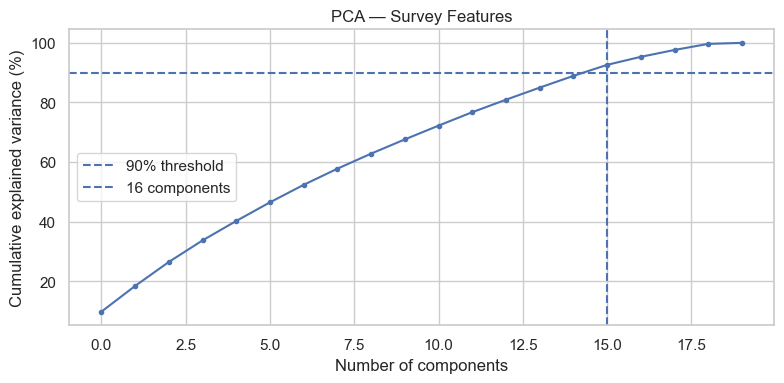

In [183]:
# PCA on survey items fitted on train only
X_pca_train = comp_survey_train[survey_cols_available].replace(-1, np.nan) if survey_cols_available else pd.DataFrame()
X_pca_test = comp_survey_test[survey_cols_available].replace(-1, np.nan) if survey_cols_available else pd.DataFrame()

if not X_pca_train.empty and X_pca_train.shape[1] > 1:
    pca_imputer_2 = SimpleImputer(strategy="median")
    X_tr_imp_pca_comp_survey = pca_imputer_2.fit_transform(X_pca_train)
    X_te_imp_pca_comp_survey = pca_imputer_2.transform(X_pca_test)
    scaler_pca_comp_survey = StandardScaler()
    X_tr_sc_pca_comp_survey = scaler_pca_comp_survey.fit_transform(X_tr_imp_pca_comp_survey)
    X_te_sc_pca_comp_survey = scaler_pca_comp_survey.transform(X_te_imp_pca_comp_survey)
    pca_comp_survey = PCA()
    pca_comp_survey.fit(X_tr_sc_pca_comp_survey)
    cumvar_2 = np.cumsum(pca_comp_survey.explained_variance_ratio_ * 100)
    n_90_2 = int(np.argmax(cumvar_2 >= 90)) + 1 if any(cumvar_2 >= 90) else len(cumvar_2)
    print(f"Components to retain 90% variance: {n_90_2} / {len(survey_cols_available)}")
    plt.figure(figsize=(8, 4))
    plt.plot(cumvar_2, marker="o", markersize=3)
    plt.axhline(90, linestyle="--", label="90% threshold")
    plt.axvline(n_90_2 - 1, linestyle="--", label=f"{n_90_2} components")
    plt.xlabel("Number of components")
    plt.ylabel("Cumulative explained variance (%)")
    plt.title("PCA — Survey Features")
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("Insufficient survey columns for PCA.")

In [184]:

FINAL_FEATURES_COMP_SURVEY = ["CompTotal_USD", "Country", "TechEndorseIntro"] + survey_cols_available
FINAL_FEATURES_COMP_SURVEY = [c for c in FINAL_FEATURES_COMP_SURVEY if c in comp_survey_train.columns]
CAT_COLS_COMP_SURVEY = [c for c in ["Country", "TechEndorseIntro"] if c in comp_survey_train.columns]

X_train_comp_survey_rf = comp_survey_train[FINAL_FEATURES_COMP_SURVEY].copy()
X_test_comp_survey_rf = comp_survey_test[FINAL_FEATURES_COMP_SURVEY].copy()

enc_comp_survey = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-2)
if CAT_COLS_COMP_SURVEY:
    X_train_comp_survey_rf[CAT_COLS_COMP_SURVEY] = enc_comp_survey.fit_transform(X_train_comp_survey_rf[CAT_COLS_COMP_SURVEY].astype(str))
    X_test_comp_survey_rf[CAT_COLS_COMP_SURVEY] = enc_comp_survey.transform(X_test_comp_survey_rf[CAT_COLS_COMP_SURVEY].astype(str))

imp_comp_survey = SimpleImputer(strategy="median")
X_train_comp_survey_imp = pd.DataFrame(imp_comp_survey.fit_transform(X_train_comp_survey_rf), columns=FINAL_FEATURES_COMP_SURVEY, index=train_global.index)
X_test_comp_survey_imp = pd.DataFrame(imp_comp_survey.transform(X_test_comp_survey_rf), columns=FINAL_FEATURES_COMP_SURVEY, index=test_global.index)

rf_comp_survey = RandomForestClassifier(n_estimators=200, max_depth=12, random_state=RANDOM_STATE, n_jobs=-1, class_weight="balanced")
t0 = time.time()
rf_comp_survey.fit(X_train_comp_survey_imp, y_train)
train_time_2 = time.time() - t0
preds_2 = rf_comp_survey.predict(X_test_comp_survey_imp)
acc_2 = accuracy_score(y_test, preds_2)
print(f"Compensation/survey RF Accuracy: {acc_2:.4f}; train time: {train_time_2:.2f}s")
print(classification_report(y_test, preds_2))

imp_df_2 = pd.DataFrame({"Feature": FINAL_FEATURES_COMP_SURVEY, "Importance": rf_comp_survey.feature_importances_}).sort_values("Importance")
display(imp_df_2.tail(15))

Compensation/survey RF Accuracy: 0.4002; train time: 1.78s
              precision    recall  f1-score   support

     Average       0.49      0.51      0.50      2259
        High       0.29      0.25      0.27      1173
         Low       0.33      0.34      0.34      1361

    accuracy                           0.40      4793
   macro avg       0.37      0.37      0.37      4793
weighted avg       0.40      0.40      0.40      4793



,Feature,Importance
14,TechOppose_11,0.042107
3,TechEndorse_1,0.042146
19,TechOppose_3,0.042146
20,TechOppose_5,0.042312
15,TechOppose_13,0.042322
5,TechEndorse_2,0.042562
6,TechEndorse_3,0.042980
12,TechEndorse_9,0.044198
10,TechEndorse_7,0.044278
7,TechEndorse_4,0.044677


In [185]:

MACRO_2 = [c for c in ["CompTotal_USD", "Country"] if c in comp_survey_train.columns]

X_champ_train = comp_survey_train[MACRO_2 + survey_cols_available].copy().reset_index(drop=True)
X_champ_test = comp_survey_test[MACRO_2 + survey_cols_available].copy().reset_index(drop=True)
X_chall_train = pd.concat([comp_survey_train[MACRO_2].reset_index(drop=True), agg_train_comp_survey.reset_index(drop=True)], axis=1)
X_chall_test = pd.concat([comp_survey_test[MACRO_2].reset_index(drop=True), agg_test_comp_survey.reset_index(drop=True)], axis=1)

for X_tr, X_te in [(X_champ_train, X_champ_test), (X_chall_train, X_chall_test)]:
    if "Country" in X_tr.columns:
        enc_country = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-2)
        X_tr[["Country"]] = enc_country.fit_transform(X_tr[["Country"]].astype(str))
        X_te[["Country"]] = enc_country.transform(X_te[["Country"]].astype(str))
    imp = SimpleImputer(strategy="median")
    X_tr[:] = imp.fit_transform(X_tr)
    X_te[:] = imp.transform(X_te)

rf_champ_2 = RandomForestClassifier(n_estimators=200, max_depth=12, random_state=RANDOM_STATE, n_jobs=-1, class_weight="balanced")
rf_chall_2 = RandomForestClassifier(n_estimators=200, max_depth=12, random_state=RANDOM_STATE, n_jobs=-1, class_weight="balanced")
rf_champ_2.fit(X_champ_train, y_train)
rf_chall_2.fit(X_chall_train, y_train)
p_champ_2 = rf_champ_2.predict(X_champ_test)
p_chall_2 = rf_chall_2.predict(X_chall_test)
print("Champion — raw survey cols")
print(classification_report(y_test, p_champ_2))
print("Challenger — 4 aggregated themes")
print(classification_report(y_test, p_chall_2))

Champion — raw survey cols
              precision    recall  f1-score   support

     Average       0.48      0.56      0.52      2259
        High       0.29      0.27      0.28      1173
         Low       0.34      0.27      0.30      1361

    accuracy                           0.41      4793
   macro avg       0.37      0.37      0.36      4793
weighted avg       0.39      0.41      0.40      4793

Challenger — 4 aggregated themes
              precision    recall  f1-score   support

     Average       0.49      0.45      0.47      2259
        High       0.27      0.34      0.30      1173
         Low       0.32      0.28      0.30      1361

    accuracy                           0.38      4793
   macro avg       0.36      0.36      0.36      4793
weighted avg       0.38      0.38      0.38      4793



In [186]:
def preprocess_work_database_block(train_global, test_global):
    cols_3 = [TARGET, "RemoteWork", "Employment", "LearnCodeChoose", "DatabaseHaveWorkedWith", "DatabaseAdmired"]
    cols_3 = [c for c in cols_3 if c in train_global.columns]
    train = train_global[cols_3].copy()
    test = test_global.reindex(columns=cols_3).copy()
    test[TARGET] = y_test.values

    sat_mapping_ = {"Low": 0, "Average": 1, "High": 2}
    train["JobSat_Score_"] = train[TARGET].map(sat_mapping_)
    test["JobSat_Score_"] = test[TARGET].map(sat_mapping_)

    if "LearnCodeChoose" in train.columns:
        fill_val = "No, I am not new to coding and did not learn new coding techniques or programming languages"
        train["LearnCodeChoose"] = train["LearnCodeChoose"].fillna(fill_val)
        test["LearnCodeChoose"] = test["LearnCodeChoose"].fillna(fill_val)
        train["LearnCodeChoose_Encoded"] = train["LearnCodeChoose"].apply(lambda x: 1 if "Yes, I am new to coding" in str(x) else 0)
        test["LearnCodeChoose_Encoded"] = test["LearnCodeChoose"].apply(lambda x: 1 if "Yes, I am new to coding" in str(x) else 0)

    if "RemoteWork" in train.columns:
        train["RemoteWork"] = train["RemoteWork"].fillna("Not Specified")
        test["RemoteWork"] = test["RemoteWork"].fillna("Not Specified")
        remote_map_ = {
            "Remote": 1,
            "Your choice (very flexible, you can come in when you want or just as needed)": 1,
            "Hybrid (some remote, leans heavy to in-person)": 2,
            "Hybrid (some in-person, leans heavy to flexibility)": 2,
            "Not Specified": 2,
            "In-person": 3,
        }
        train["RemoteWork_Encoded"] = train["RemoteWork"].map(remote_map_).fillna(2)
        test["RemoteWork_Encoded"] = test["RemoteWork"].map(remote_map_).fillna(2)

    if "Employment" in train.columns:
        emp_map_ = {
            "Independent contractor, freelancer, or self-employed": 1,
            "Retired": 1,
            "Employed": 2,
            "I prefer not to say": 3,
            "Student": 3,
            "Not employed": 4,
        }
        train["Employment_Encoded"] = train["Employment"].map(emp_map_).fillna(3)
        test["Employment_Encoded"] = test["Employment"].map(emp_map_).fillna(3)

    if "DatabaseAdmired" in train.columns:
        train["DatabaseAdmired"] = train["DatabaseAdmired"].fillna("None")
        test["DatabaseAdmired"] = test["DatabaseAdmired"].fillna("None")
        elite_admired = ["Cassandra", "Cosmos DB"]
        train["DB_Admired_Elite"] = train["DatabaseAdmired"].apply(lambda x: 1 if any(db in str(x) for db in elite_admired) else 0)
        test["DB_Admired_Elite"] = test["DatabaseAdmired"].apply(lambda x: 1 if any(db in str(x) for db in elite_admired) else 0)

    if "DatabaseHaveWorkedWith" in train.columns:
        train["DatabaseHaveWorkedWith"] = train["DatabaseHaveWorkedWith"].fillna("None")
        test["DatabaseHaveWorkedWith"] = test["DatabaseHaveWorkedWith"].fillna("None")
        elite_worked = ["Datomic", "Cockroachdb"]
        train["DB_Worked_Elite"] = train["DatabaseHaveWorkedWith"].apply(lambda x: 1 if any(db in str(x) for db in elite_worked) else 0)
        test["DB_Worked_Elite"] = test["DatabaseHaveWorkedWith"].apply(lambda x: 1 if any(db in str(x) for db in elite_worked) else 0)

    raw_cols = ["RemoteWork", "Employment", "LearnCodeChoose", "DatabaseHaveWorkedWith", "DatabaseAdmired", TARGET, "JobSat_Score_"]
    X_train = train.drop(columns=[c for c in raw_cols if c in train.columns]).copy()
    X_test = test.drop(columns=[c for c in raw_cols if c in test.columns]).copy()
    X_train = X_train.apply(pd.to_numeric, errors="coerce").fillna(0)
    X_test = X_test.reindex(columns=X_train.columns, fill_value=0).apply(pd.to_numeric, errors="coerce").fillna(0)
    return X_train, X_test

X_train_work_database, X_test_work_database = preprocess_work_database_block(train_global, test_global)
print("Work/database final:", X_train_work_database.shape, X_test_work_database.shape)
display(X_train_work_database.head())

Work/database final: (19168, 5) (4793, 5)


,LearnCodeChoose_Encoded,RemoteWork_Encoded,Employment_Encoded,DB_Admired_Elite,DB_Worked_Elite
0,0,1,2,0,0
1,0,2,2,0,0
2,0,2,3,0,0
3,0,1,1,0,0
4,0,2,2,0,0


In [187]:
def preprocess_tools_platforms_block(train_global, test_global):
    tools_platform_cols = []
    for c in train_global.columns:
        if c.startswith("Tool") or c.startswith("DevEnvs") or c.startswith("Webframe") or c.startswith("CommPlat") or c.startswith("OpSys"):
            tools_platform_cols.append(c)
    extra_cols = ["PurchaseInfluence", "EmploymentAddl", "Industry", "AgentUsesGeneral"]
    tools_platform_cols.extend([c for c in extra_cols if c in train_global.columns])
    tools_platform_cols = list(dict.fromkeys(tools_platform_cols))
    if TARGET not in tools_platform_cols:
        tools_platform_cols.append(TARGET)

    train = train_global[tools_platform_cols].copy()
    test = test_global.reindex(columns=tools_platform_cols).copy()
    test[TARGET] = y_test.values

    many_nulls = [c for c in tools_platform_cols if c != TARGET and train[c].isnull().mean() > 0.70]
    train = train.drop(columns=many_nulls, errors="ignore")
    test = test.drop(columns=many_nulls, errors="ignore")
    print("Tools/platform columns removed for >70% missing in TRAIN:", many_nulls)

    category = [c for c in train.columns if c != TARGET and train[c].dtype == "object"]
    numeric = [c for c in train.columns if c != TARGET and train[c].dtype != "object"]

    def is_multi_value(df, col):
        return df[col].dropna().astype(str).str.contains(";").any()

    multi_value_cols = [c for c in category if is_multi_value(train, c)]
    single_value_cols = [c for c in category if c not in multi_value_cols]
    print("Multi-value columns:", multi_value_cols)
    print("Single-value columns:", single_value_cols)

    for col in single_value_cols:
        mode_value = train[col].mode(dropna=True)
        fill_value = mode_value.iloc[0] if not mode_value.empty else "Unknown"
        train[col] = train[col].fillna(fill_value)
        test[col] = test[col].fillna(fill_value)

    for col in numeric:
        median_value = train[col].median()
        fill_value = median_value if pd.notna(median_value) else 0
        train[col] = train[col].fillna(fill_value)
        test[col] = test[col].fillna(fill_value)

    for col in multi_value_cols:
        train[col] = train[col].fillna("Unknown")
        test[col] = test[col].fillna("Unknown")

    drop_cols = [c for c in ["ToolCountWork", "ToolCountPersonal"] if c in train.columns]
    train = train.drop(columns=drop_cols, errors="ignore")
    test = test.drop(columns=drop_cols, errors="ignore")
    single_value_cols = [c for c in single_value_cols if c not in drop_cols]
    multi_value_cols = [c for c in multi_value_cols if c not in drop_cols]
    print("Dropped count columns:", drop_cols)

    train, test, mlbs = multi_hot_train_test(train, test, multi_value_cols, sep="_")
    preprocessing_objects["tools_platforms_mlbs"] = mlbs

    single_cols_present = [c for c in single_value_cols if c in train.columns]
    train = pd.get_dummies(train, columns=single_cols_present, drop_first=True, dtype=int)
    test = pd.get_dummies(test, columns=single_cols_present, drop_first=True, dtype=int)
    test = test.reindex(columns=train.columns, fill_value=0)

    X_train = train.drop(columns=[TARGET], errors="ignore").apply(pd.to_numeric, errors="coerce").fillna(0)
    X_test = test.drop(columns=[TARGET], errors="ignore").reindex(columns=X_train.columns, fill_value=0).apply(pd.to_numeric, errors="coerce").fillna(0)

    binary_cols = [c for c in X_train.columns if set(X_train[c].dropna().unique()).issubset({0, 1})]
    rare_cols = [c for c in binary_cols if X_train[c].sum() < 20]
    X_train_filtered = X_train.drop(columns=rare_cols)
    X_test_filtered = X_test.drop(columns=rare_cols)

    k = min(30, X_train_filtered.shape[1])
    selector = SelectKBest(score_func=lambda X, y: mutual_info_classif(X, y, discrete_features=True, random_state=RANDOM_STATE), k=k)
    selector.fit(X_train_filtered, y_train_encoded)
    selected_features = X_train_filtered.columns[selector.get_support()].tolist()
    selected_scores = selector.scores_[selector.get_support()]
    selected_scores_df = pd.DataFrame({"feature": selected_features, "mutual_info_score": selected_scores}).sort_values("mutual_info_score", ascending=False).reset_index(drop=True)

    print("Tools/platforms removed rare columns:", len(rare_cols))
    print("Tools/platforms selected features:", len(selected_features))
    display(selected_scores_df.head(30))

    return X_train_filtered[selected_features].copy(), X_test_filtered[selected_features].copy(), selected_scores_df, X_train_filtered

X_train_tools_platforms, X_test_tools_platforms, mi_tools_platforms, X_tools_platforms_filtered = preprocess_tools_platforms_block(train_global, test_global)
print("Tools/platforms final:", X_train_tools_platforms.shape, X_test_tools_platforms.shape)

Tools/platform columns removed for >70% missing in TRAIN: []
Multi-value columns: ['WebframeHaveWorkedWith', 'WebframeWantToWorkWith', 'WebframeAdmired', 'DevEnvsHaveWorkedWith', 'DevEnvsWantToWorkWith', 'DevEnvsAdmired', 'OpSysPersonal use', 'OpSysProfessional use', 'CommPlatformHaveWorkedWith', 'CommPlatformWantToWorkWith', 'CommPlatformAdmired', 'EmploymentAddl']
Single-value columns: ['WebframeChoice', 'DevEnvsChoice', 'PurchaseInfluence', 'Industry']
Dropped count columns: ['ToolCountWork', 'ToolCountPersonal']
Tools/platforms removed rare columns: 0
Tools/platforms selected features: 30


,feature,mutual_info_score
0,"PurchaseInfluence_Yes, I influenced the purcha...",0.006107
1,EmploymentAddl_None of the above,0.001296
2,EmploymentAddl_Caring for dependents (children...,0.001198
3,"PurchaseInfluence_Yes, I endorsed a tool that ...",0.001012
4,DevEnvsHaveWorkedWith_Claude Code,0.000966
5,"PurchaseInfluence_Yes, I endorsed a tool that ...",0.000891
6,EmploymentAddl_Volunteering (regularly),0.000836
7,OpSysProfessional use_MacOS,0.000615
8,EmploymentAddl_Transitioning to retirement (gr...,0.000587
9,OpSysProfessional use_iOS,0.000561


Tools/platforms final: (19168, 30) (4793, 30)


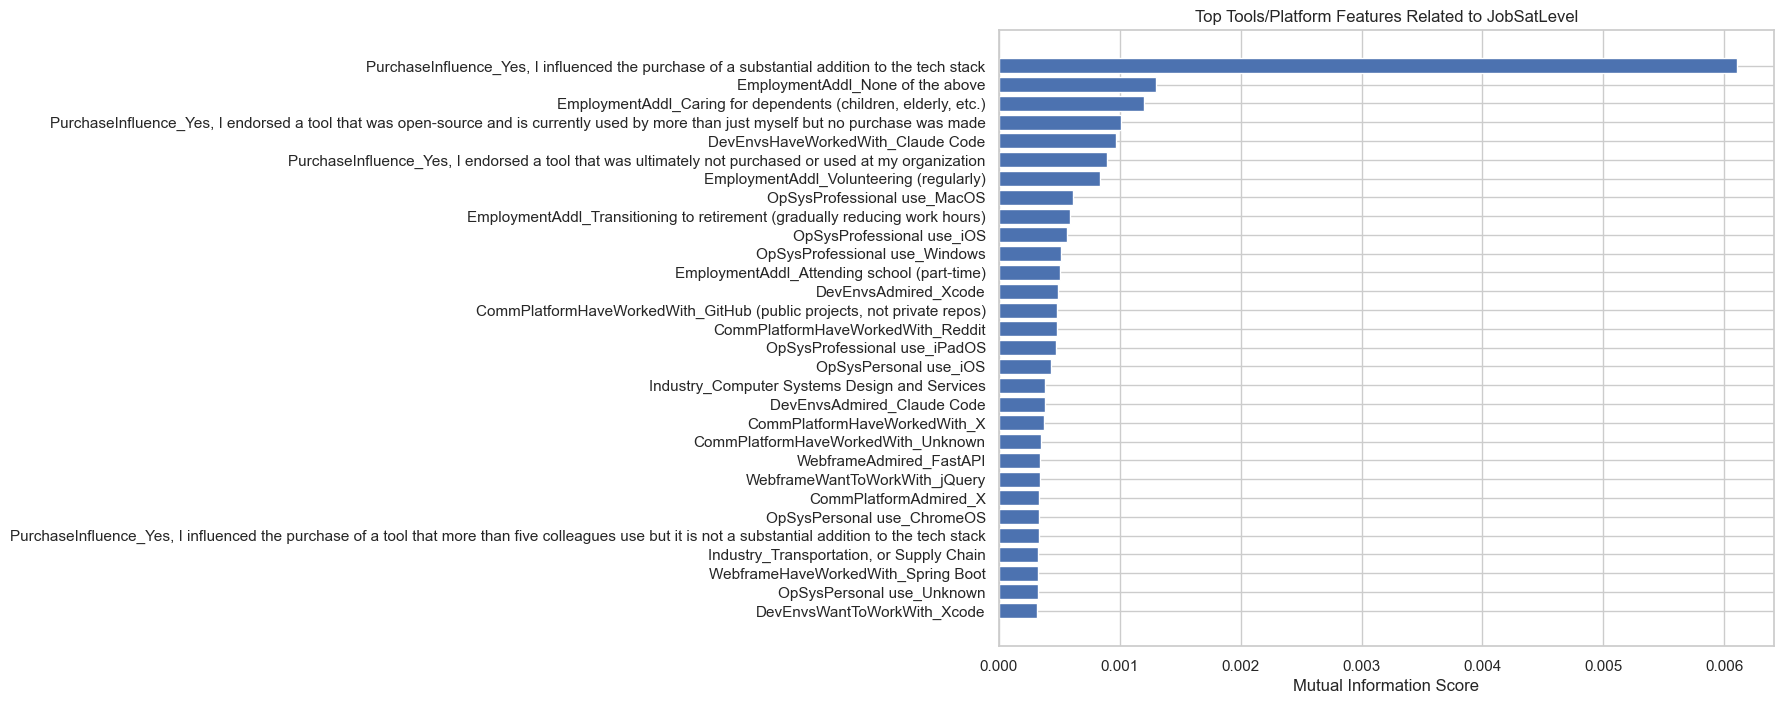

PurchaseInfluence_Yes, I influenced the purchase of a substantial addition to the tech stack


JobSatLevel,Average,High,Low,All
"PurchaseInfluence_Yes, I influenced the purchase of a substantial addition to the tech stack",,,,
0,7343,3456,4667,15466
1,1694,1233,775,3702
All,9037,4689,5442,19168


EmploymentAddl_None of the above


JobSatLevel,Average,High,Low,All
EmploymentAddl_None of the above,,,,
0,5099,2866,2957,10922
1,3938,1823,2485,8246
All,9037,4689,5442,19168


EmploymentAddl_Caring for dependents (children, elderly, etc.)


JobSatLevel,Average,High,Low,All
"EmploymentAddl_Caring for dependents (children, elderly, etc.)",,,,
0,7220,3602,4476,15298
1,1817,1087,966,3870
All,9037,4689,5442,19168


PurchaseInfluence_Yes, I endorsed a tool that was open-source and is currently used by more than just myself but no purchase was made


JobSatLevel,Average,High,Low,All
"PurchaseInfluence_Yes, I endorsed a tool that was open-source and is currently used by more than just myself but no purchase was made",,,,
0,7514,4015,4724,16253
1,1523,674,718,2915
All,9037,4689,5442,19168


DevEnvsHaveWorkedWith_Claude Code


JobSatLevel,Average,High,Low,All
DevEnvsHaveWorkedWith_Claude Code,,,,
0,8359,4242,5099,17700
1,678,447,343,1468
All,9037,4689,5442,19168


In [188]:
# Tools/platforms MI bar chart and crosstab checks
if not mi_tools_platforms.empty:
    plot_df = mi_tools_platforms.sort_values("mutual_info_score", ascending=True)
    plt.figure(figsize=(10, 8))
    plt.barh(plot_df["feature"], plot_df["mutual_info_score"])
    plt.title("Top Tools/Platform Features Related to JobSatLevel")
    plt.xlabel("Mutual Information Score")
    plt.tight_layout()
    plt.show()

    for feature in mi_tools_platforms["feature"].head(5):
        print("=" * 80)
        print(feature)
        display(pd.crosstab(X_tools_platforms_filtered[feature], y_train, margins=True))

In [189]:
def preprocess_stack_overflow_block(train_global, test_global):
    features_4 = [
        "SOTagsHaveWorkedWith", "SOTagsWantToWorkWith", "SOTagsAdmired",
        "SOTagsHaveEntry", "SOAccount", "SOVisitFreq", "SOPartFreq",
        "SOComm", "SOFriction", "SO_Actions_1", "SO_Actions_16",
        "SO_Actions_3", "SO_Actions_4", "SO_Actions_6", "SO_Actions_7", "SO_Actions_15",
    ]
    features_available = [f for f in features_4 if f in train_global.columns]
    missing_info = train_global[features_available].isnull().mean() * 100
    cols_to_test = [f for f in features_available if missing_info[f] < 90]
    print("Stack Overflow features used:", cols_to_test)

    if not cols_to_test:
        return pd.DataFrame(index=train_global.index), pd.DataFrame(index=test_global.index), pd.Series(dtype=float)

    train_proc = train_global[cols_to_test].copy()
    test_proc = test_global[cols_to_test].copy()
    encoders = {}
    for col in cols_to_test:
        train_proc[col] = train_proc[col].fillna("Missing").astype(str)
        test_proc[col] = test_proc[col].fillna("Missing").astype(str)
        le = LabelEncoder()
        train_proc[col] = le.fit_transform(train_proc[col])
        known = set(le.classes_)
        test_proc[col] = test_proc[col].apply(lambda x: x if x in known else "Missing")
        test_proc[col] = le.transform(test_proc[col])
        encoders[col] = le
    preprocessing_objects["stack_overflow_encoders"] = encoders

    mi_scores = mutual_info_classif(train_proc, y_train_encoded, discrete_features=True, random_state=RANDOM_STATE)
    mi_results = pd.Series(mi_scores, index=cols_to_test).sort_values(ascending=False)
    print("Stack Overflow MI results:")
    print(mi_results)

    drop_cols = [
        "SO_Actions_15", "SO_Actions_3", "SO_Actions_7", "SO_Actions_4", "SO_Actions_6",
        "SOVisitFreq", "SO_Actions_1", "SO_Actions_16", "SOFriction", "SOAccount",
    ]
    train_proc = train_proc.drop(columns=drop_cols, errors="ignore")
    test_proc = test_proc.drop(columns=drop_cols, errors="ignore")
    test_proc = test_proc.reindex(columns=train_proc.columns, fill_value=0)
    return train_proc, test_proc, mi_results

X_train_stack_overflow, X_test_stack_overflow, mi_stack_overflow = preprocess_stack_overflow_block(train_global, test_global)
print("Stack Overflow final:", X_train_stack_overflow.shape, X_test_stack_overflow.shape)

Stack Overflow features used: ['SOTagsHaveWorkedWith', 'SOTagsWantToWorkWith', 'SOTagsAdmired', 'SOAccount', 'SOVisitFreq', 'SOPartFreq', 'SOComm', 'SOFriction', 'SO_Actions_1', 'SO_Actions_16', 'SO_Actions_3', 'SO_Actions_4', 'SO_Actions_6', 'SO_Actions_7', 'SO_Actions_15']
Stack Overflow MI results:
SOTagsWantToWorkWith    0.082770
SOTagsHaveWorkedWith    0.075501
SOTagsAdmired           0.048190
SOComm                  0.003110
SOPartFreq              0.002206
SO_Actions_15           0.001334
SO_Actions_3            0.001315
SO_Actions_7            0.001289
SO_Actions_4            0.001241
SO_Actions_6            0.001207
SOVisitFreq             0.001030
SO_Actions_1            0.000977
SO_Actions_16           0.000960
SOFriction              0.000854
SOAccount               0.000551
dtype: float64
Stack Overflow final: (19168, 5) (4793, 5)


In [190]:
feature_blocks_train = [
    X_train_main_ai,
    X_train_ai_agent,
    X_train_comp_survey_imp,
    X_train_work_database,
    X_train_stack_overflow,
    X_train_tools_platforms,
]

feature_blocks_test = [
    X_test_main_ai,
    X_test_ai_agent,
    X_test_comp_survey_imp,
    X_test_work_database,
    X_test_stack_overflow,
    X_test_tools_platforms,
]

X_train_final = pd.concat([b.reset_index(drop=True) for b in feature_blocks_train], axis=1)
X_test_final = pd.concat([b.reset_index(drop=True) for b in feature_blocks_test], axis=1)

X_train_final = make_unique_columns(X_train_final)
X_test_final = make_unique_columns(X_test_final)
X_test_final = X_test_final.reindex(columns=X_train_final.columns, fill_value=0)


X_train_final = X_train_final.apply(pd.to_numeric, errors="coerce").fillna(0)
X_test_final = X_test_final.reindex(columns=X_train_final.columns, fill_value=0).apply(pd.to_numeric, errors="coerce").fillna(0)

X_train_final_unscaled = X_train_final.copy()
X_test_final_unscaled = X_test_final.copy()

final_scaler = StandardScaler()

X_train_final = pd.DataFrame(
    final_scaler.fit_transform(X_train_final_unscaled),
    columns=X_train_final_unscaled.columns,
    index=X_train_final_unscaled.index,
)

X_test_final = pd.DataFrame(
    final_scaler.transform(X_test_final_unscaled),
    columns=X_test_final_unscaled.columns,
    index=X_test_final_unscaled.index,
)


preprocessing_objects["final_scaler"] = final_scaler
preprocessing_objects["final_feature_columns_before_scaling"] = list(X_train_final_unscaled.columns)


print("X_train_final:", X_train_final.shape)
print("X_test_final:", X_test_final.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)
print("Remaining nulls train:", int(X_train_final.isnull().sum().sum()))
print("Remaining nulls test:", int(X_test_final.isnull().sum().sum()))
print("Example final columns:")
print(list(X_train_final.columns[:25]))

X_train_final: (19168, 79)
X_test_final: (4793, 79)
y_train: (19168,)
y_test: (4793,)
Remaining nulls train: 0
Remaining nulls test: 0
Example final columns:
['NewRole_I have neither consider or transitioned into a new career or industry', 'NewRole_I have strongly considered changing my career and/or the industry I work in', 'NewRole_I have somewhat considered changing my career and/or the industry I work in', 'AIThreat_No', 'AIModelsAdmired;openAI Image generating models', "AIToolDon't plan to use AI for this task;Writing code", "AIToolDon't plan to use AI for this task;Project planning", 'LearnCode;School (i.e., University, College, etc)', 'AIModelsWantToWorkWith;X Grok models', 'AIComplex_Neither good or bad at handling complex tasks', 'WorkExp', 'DevType_encoded', 'OrgSize', 'ICorPM', 'AI_Challenges_Total', 'AIAgent_Uses_Count', 'CompTotal_USD', 'Country', 'TechEndorseIntro', 'TechEndorse_1', 'TechEndorse_13', 'TechEndorse_2', 'TechEndorse_3', 'TechEndorse_4', 'TechEndorse_5']


In [191]:
final_selected_train_df = X_train_final.copy()
final_selected_train_df[TARGET] = y_train_encoded.values

final_selected_test_df = X_test_final.copy()
final_selected_test_df[TARGET] = y_test_encoded.values

display(final_selected_train_df.head())

,NewRole_I have neither consider or transitioned into a new career or industry,NewRole_I have strongly considered changing my career and/or the industry I work in,NewRole_I have somewhat considered changing my career and/or the industry I work in,AIThreat_No,AIModelsAdmired;openAI Image generating models,AIToolDon't plan to use AI for this task;Writing code,AIToolDon't plan to use AI for this task;Project planning,"LearnCode;School (i.e., University, College, etc)",AIModelsWantToWorkWith;X Grok models,AIComplex_Neither good or bad at handling complex tasks,...,EmploymentAddl_None of the above,EmploymentAddl_Transitioning to retirement (gradually reducing work hours),EmploymentAddl_Volunteering (regularly),"PurchaseInfluence_Yes, I endorsed a tool that was open-source and is currently used by more than just myself but no purchase was made","PurchaseInfluence_Yes, I endorsed a tool that was ultimately not purchased or used at my organization","PurchaseInfluence_Yes, I influenced the purchase of a substantial addition to the tech stack","PurchaseInfluence_Yes, I influenced the purchase of a tool that more than five colleagues use but it is not a substantial addition to the tech stack",Industry_Computer Systems Design and Services,"Industry_Transportation, or Supply Chain",JobSatLevel
0,-0.938648,-0.394466,1.544079,-1.341750,-0.282751,-0.484575,-1.012283,-0.305271,-0.199544,-0.389951,...,1.150878,-0.128003,-0.370991,-0.423499,-0.189431,-0.489248,-0.290637,-0.145803,-0.15889,0
1,1.065362,-0.394466,-0.647635,0.745296,-0.282751,2.063664,0.987866,-0.305271,-0.199544,-0.389951,...,1.150878,-0.128003,-0.370991,2.361280,-0.189431,-0.489248,-0.290637,-0.145803,-0.15889,1
2,1.065362,-0.394466,-0.647635,0.745296,-0.282751,-0.484575,-1.012283,-0.305271,-0.199544,-0.389951,...,-0.868902,-0.128003,-0.370991,-0.423499,-0.189431,-0.489248,-0.290637,-0.145803,-0.15889,1
3,-0.938648,-0.394466,1.544079,-1.341750,-0.282751,-0.484575,-1.012283,-0.305271,5.011431,2.564427,...,-0.868902,-0.128003,-0.370991,2.361280,-0.189431,-0.489248,-0.290637,6.858579,-0.15889,0
4,-0.938648,-0.394466,1.544079,-1.341750,-0.282751,-0.484575,0.987866,-0.305271,-0.199544,-0.389951,...,1.150878,-0.128003,-0.370991,-0.423499,-0.189431,2.043952,-0.290637,-0.145803,-0.15889,0


In [192]:
# baseline_rf = RandomForestClassifier(
#     n_estimators=200,
#     max_depth=12,
#     random_state=RANDOM_STATE,
#     n_jobs=-1,
#     class_weight="balanced",
# )

# t0 = time.time()
# baseline_rf.fit(X_train_final, y_train)
# train_time = time.time() - t0
# preds = baseline_rf.predict(X_test_final)

# print("Baseline Random Forest")
# print(f"Train time: {train_time:.2f}s")
# print(f"Accuracy: {accuracy_score(y_test, preds):.4f}")
# print(f"Balanced accuracy: {balanced_accuracy_score(y_test, preds):.4f}")
# print(f"Macro F1: {f1_score(y_test, preds, average='macro'):.4f}")
# print(classification_report(y_test, preds))

# cm = confusion_matrix(y_test, preds, labels=target_order)
# plt.figure(figsize=(6, 4))
# sns.heatmap(cm, annot=True, fmt="d", xticklabels=target_order, yticklabels=target_order)
# plt.xlabel("Predicted")
# plt.ylabel("Actual")
# plt.title("Baseline Random Forest — Confusion Matrix")
# plt.tight_layout()
# plt.show()

In [193]:

# X_train = X_train_final
# X_test = X_test_final

# tuning_results = {}

# print("=" * 60)
# print("DecisionTreeClassifier checks")
# print("=" * 60)
# dt_max_depth_vals = [3, 5, 10, None]
# dt_min_split_vals = [2, 5, 10]
# dt_depth_results = {}
# for d in dt_max_depth_vals:
#     clf = DecisionTreeClassifier(max_depth=d, min_samples_split=2, random_state=RANDOM_STATE)
#     clf.fit(X_train, y_train)
#     acc = accuracy_score(y_test, clf.predict(X_test))
#     dt_depth_results[str(d)] = acc
#     print(f"max_depth={d}: accuracy={acc:.4f}")
# best_dt_depth = dt_max_depth_vals[np.argmax(list(dt_depth_results.values()))]

# dt_split_results = {}
# for s in dt_min_split_vals:
#     clf = DecisionTreeClassifier(max_depth=best_dt_depth, min_samples_split=s, random_state=RANDOM_STATE)
#     clf.fit(X_train, y_train)
#     acc = accuracy_score(y_test, clf.predict(X_test))
#     dt_split_results[str(s)] = acc
#     print(f"min_samples_split={s}: accuracy={acc:.4f}")
# best_dt_split = dt_min_split_vals[np.argmax(list(dt_split_results.values()))]

# tuning_results["DecisionTree"] = {
#     "max_depth": dt_depth_results,
#     "min_samples_split": dt_split_results,
#     "best_params": {"max_depth": best_dt_depth, "min_samples_split": best_dt_split},
# }

# print()
# print("=" * 60)
# print("RandomForestClassifier checks")
# print("=" * 60)
# rf_n_estimators_vals = [50, 100]
# rf_max_depth_vals = [3]
# rf_n_results = {}
# for n in rf_n_estimators_vals:
#     clf = RandomForestClassifier(n_estimators=n, max_depth=None, random_state=RANDOM_STATE, n_jobs=1)
#     clf.fit(X_train, y_train)
#     acc = accuracy_score(y_test, clf.predict(X_test))
#     rf_n_results[str(n)] = acc
#     print(f"n_estimators={n}: accuracy={acc:.4f}")
# best_rf_n = rf_n_estimators_vals[np.argmax(list(rf_n_results.values()))]

# rf_depth_results = {"not_run": "skipped to keep notebook runtime reasonable"}
# best_rf_depth = None
# print("Random Forest max_depth loop skipped to keep this merged notebook runnable.")

# tuning_results["RandomForest"] = {
#     "n_estimators": rf_n_results,
#     "max_depth": rf_depth_results,
#     "best_params": {"n_estimators": best_rf_n, "max_depth": best_rf_depth},
# }

# print()
# print("FINAL BEST PARAMETERS")
# for model_name, results in tuning_results.items():
#     print(model_name, results["best_params"])


In [194]:
final_selected_train_df.to_csv("final_train_data.csv", index = False)
final_selected_test_df.to_csv("final_test_data.csv", index = False)

In [195]:
X_train.columns

Index(['NewRole_I have neither consider or transitioned into a new career or industry',
       'NewRole_I have strongly considered changing my career and/or the industry I work in',
       'NewRole_I have somewhat considered changing my career and/or the industry I work in',
       'AIThreat_No', 'AIModelsAdmired;openAI Image generating models',
       'AIToolDon't plan to use AI for this task;Writing code',
       'AIToolDon't plan to use AI for this task;Project planning',
       'LearnCode;School (i.e., University, College, etc)',
       'AIModelsWantToWorkWith;X Grok models',
       'AIComplex_Neither good or bad at handling complex tasks', 'WorkExp',
       'DevType_encoded', 'OrgSize', 'ICorPM', 'AI_Challenges_Total',
       'AIAgent_Uses_Count', 'CompTotal_USD', 'Country', 'TechEndorseIntro',
       'TechEndorse_1', 'TechEndorse_13', 'TechEndorse_2', 'TechEndorse_3',
       'TechEndorse_4', 'TechEndorse_5', 'TechEndorse_6', 'TechEndorse_7',
       'TechEndorse_8', 'TechEndorse_9

In [ ]:


import pickle
from pathlib import Path
import pandas as pd
import numpy as np

Path("preprocessing_objects").mkdir(exist_ok=True)

def mode_or_default(series, default="Unknown"):
    mode_values = series.dropna().mode()
    if mode_values.empty:
        return default
    return mode_values.iloc[0]

target_col = TARGET

raw_preprocessing = {
    "target_col": target_col,
    "target_mapping": {"Low": 0, "Average": 1, "High": 2},
    "final_feature_columns": list(X_train_final.columns),
    "dropped_high_missing_columns": cols_to_drop_high_missing,
    "scaler" : final_scaler
}

# ============================================================
# 1) Main AI + WorkExp block
# ============================================================

main_ai_add_cols = ["WorkExp", "NewRole", "LearnCodeAI", "LearnCode"]
main_ai_selected_cols = [
    c for c in first_21_ai_cols + main_ai_add_cols + [target_col]
    if c in train_global.columns
]

main_ai_multi_cols = [
    "AILearnHow",
    "AIModelsHaveWorkedWith",
    "AIModelsWantToWorkWith",
    "AIModelsAdmired",
    "AIToolCurrently partially AI",
    "AIToolDon't plan to use AI for this task",
    "AIToolPlan to partially use AI",
    "AIToolPlan to mostly use AI",
    "AIToolCurrently mostly AI",
    "AIFrustration",
    "LearnCode",
]
main_ai_multi_cols = [c for c in main_ai_multi_cols if c in train_global.columns]

main_ai_fill_values = {}
for c in main_ai_selected_cols:
    if c != target_col and c not in main_ai_multi_cols and c in train_global.columns:
        if train_global[c].dtype == "object":
            main_ai_fill_values[c] = mode_or_default(train_global[c], "Unknown")

raw_preprocessing["main_ai"] = {
    "selected_cols": main_ai_selected_cols,
    "multi_cols": main_ai_multi_cols,
    "fill_values": main_ai_fill_values,
    "workexp_median": preprocessing_objects.get(
        "main_ai_workexp_median",
        train_global["WorkExp"].median() if "WorkExp" in train_global.columns else 0,
    ),
    "mlbs": preprocessing_objects.get("main_ai_mlbs", {}),
    "ohe": preprocessing_objects.get("main_ai_ohe", None),
    "output_columns": list(X_train_main_ai.columns),
}

# ============================================================
# 2) AI Agent + Developer profile block
# ============================================================

ai_agent_cols = [
    "AIAgent_Uses",
    "AIAgentImpactSomewhat agree",
    "AIAgentImpactNeutral",
    "AIAgentImpactSomewhat disagree",
    "AIAgentImpactStrongly agree",
    "AIAgentImpactStrongly disagree",
    "AIAgentChallengesNeutral",
    "AIAgentChallengesSomewhat disagree",
    "AIAgentChallengesStrongly agree",
    "AIAgentChallengesSomewhat agree",
    "AIAgentChallengesStrongly disagree",
    "AIAgentKnowledge",
    "AIAgentKnowWrite",
    "AIAgentOrchestration",
    "AIAgentOrchWrite",
    "AIAgentObserveSecure",
    "AIAgentObsWrite",
    "AIAgentExternal",
    "AIAgentExtWrite",
    "AIHuman",
    "AIOpen",
    "ICorPM",
    "YearsCode",
    "DevType",
    "OrgSize",
    target_col,
]
ai_agent_cols = [c for c in ai_agent_cols if c in train_global.columns]

agree_score = {
    "AIAgentChallengesStrongly disagree": 1,
    "AIAgentChallengesSomewhat disagree": 2,
    "AIAgentChallengesNeutral": 3,
    "AIAgentChallengesSomewhat agree": 4,
    "AIAgentChallengesStrongly agree": 5,
}

challenge_cols = [
    "Integrating AI agents with my existing tools and workflows can be difficult.",
    "My company's IT and/or InfoSec teams have strict rules that do not allow me to use AI agent tools or platforms",
    "I am concerned about the accuracy of the information provided by AI agents.",
    "It takes significant time and effort to learn how to use AI agents effectively.",
    "The cost of using certain AI agent platforms is a barrier.",
    "I have concerns about the security and privacy of data when using AI agents.",
]

years_median = 0
years_clip = [0, 0]
if "YearsCode" in train_global.columns:
    years_numeric = pd.to_numeric(train_global["YearsCode"], errors="coerce")
    years_median = years_numeric.median()
    q1, q3 = years_numeric.fillna(years_median).quantile([0.25, 0.75])
    iqr = q3 - q1
    years_clip = [q1 - 1.5 * iqr, q3 + 1.5 * iqr]

org_map = {
    "Just me - I am a freelancer, sole proprietor, etc.": 0,
    "Less than 20 employees": 1,
    "20 to 99 employees": 2,
    "100 to 499 employees": 3,
    "500 to 999 employees": 4,
    "1,000 to 4,999 employees": 5,
    "5,000 to 9,999 employees": 6,
    "10,000 or more employees": 7,
    "Unknown": 8,
    "I don't know": 8,
}

jobsat_map_for_dev = {"Low": 1, "Average": 2, "High": 3, 0: 1, 1: 2, 2: 3}
dev_mean = {}
global_dev_mean = 2
if "DevType" in train_global.columns:
    temp = train_global[[target_col, "DevType"]].copy()
    temp["_target_num"] = temp[target_col].map(jobsat_map_for_dev)
    dev_mean = temp.groupby("DevType")["_target_num"].mean().to_dict()
    global_dev_mean = temp["_target_num"].mean()

aihuman_columns = []
if "AIHuman" in train_global.columns:
    aihuman_train = train_global["AIHuman"].fillna("").astype(str).str.get_dummies(sep=";")
    aihuman_train.columns = ["AIHuman_" + c.strip().replace(" ", "_") for c in aihuman_train.columns]
    aihuman_columns = list(aihuman_train.columns)

raw_preprocessing["ai_agent"] = {
    "cols": ai_agent_cols,
    "agree_score": agree_score,
    "challenge_cols": challenge_cols,
    "years_median": years_median,
    "years_clip": years_clip,
    "org_map": org_map,
    "dev_mean": dev_mean,
    "global_dev_mean": global_dev_mean,
    "icorpm_map": preprocessing_objects.get("ai_agent_icorpm_map", {"Unknown": 0}),
    "aihuman_columns": aihuman_columns,
    "selected_features": list(X_train_ai_agent.columns),
}

# ============================================================
# 3) Compensation + tech attitude block
# ============================================================

raw_preprocessing["comp_survey"] = {
    "rates_to_usd": RATES_TO_USD,
    "survey_cols_available": survey_cols_available,
    "country_mode_train": country_mode_train if "country_mode_train" in globals() else "Unknown",
    "country_to_currency_train": country_to_currency_train if "country_to_currency_train" in globals() else {},
    "q99_train": q99_train if "q99_train" in globals() else None,
    "final_features": FINAL_FEATURES_COMP_SURVEY,
    "cat_cols": CAT_COLS_COMP_SURVEY,
    "ordinal_encoder": enc_comp_survey,
    "median_imputer": imp_comp_survey,
}

# ============================================================
# 4) Work + database block
# ============================================================

raw_preprocessing["work_database"] = {
    "cols": [c for c in [target_col, "RemoteWork", "Employment", "LearnCodeChoose", "DatabaseHaveWorkedWith", "DatabaseAdmired"] if c in train_global.columns],
    "output_columns": list(X_train_work_database.columns),
    "learn_code_fill": "No, I am not new to coding and did not learn new coding techniques or programming languages",
    "remote_map": {
        "Remote": 1,
        "Your choice (very flexible, you can come in when you want or just as needed)": 1,
        "Hybrid (some remote, leans heavy to in-person)": 2,
        "Hybrid (some in-person, leans heavy to flexibility)": 2,
        "Not Specified": 2,
        "In-person": 3,
    },
    "employment_map": {
        "Independent contractor, freelancer, or self-employed": 1,
        "Retired": 1,
        "Employed": 2,
        "I prefer not to say": 3,
        "Student": 3,
        "Not employed": 4,
    },
    "elite_admired": ["Cassandra", "Cosmos DB"],
    "elite_worked": ["Datomic", "Cockroachdb"],
}

# ============================================================
# 5) Tools + platforms block
# ============================================================

tools_platform_cols = []
for c in train_global.columns:
    if str(c).startswith("Tool") or str(c).startswith("DevEnvs") or str(c).startswith("Webframe") or str(c).startswith("CommPlat") or str(c).startswith("OpSys"):
        tools_platform_cols.append(c)

extra_cols = ["PurchaseInfluence", "EmploymentAddl", "Industry", "AgentUsesGeneral"]
tools_platform_cols.extend([c for c in extra_cols if c in train_global.columns])
tools_platform_cols = list(dict.fromkeys(tools_platform_cols))
if target_col not in tools_platform_cols:
    tools_platform_cols.append(target_col)

tools_train = train_global[tools_platform_cols].copy()
tools_many_nulls = [
    c for c in tools_platform_cols
    if c != target_col and tools_train[c].isnull().mean() > 0.70
]
tools_train = tools_train.drop(columns=tools_many_nulls, errors="ignore")

tools_category_cols = [
    c for c in tools_train.columns
    if c != target_col and tools_train[c].dtype == "object"
]
tools_numeric_cols = [
    c for c in tools_train.columns
    if c != target_col and tools_train[c].dtype != "object"
]

def _is_multi_value(df, col):
    return df[col].dropna().astype(str).str.contains(";").any()

tools_multi_value_cols = [c for c in tools_category_cols if _is_multi_value(tools_train, c)]
tools_single_value_cols = [c for c in tools_category_cols if c not in tools_multi_value_cols]

tools_drop_cols = [c for c in ["ToolCountWork", "ToolCountPersonal"] if c in tools_train.columns]
tools_multi_value_cols = [c for c in tools_multi_value_cols if c not in tools_drop_cols]
tools_single_value_cols = [c for c in tools_single_value_cols if c not in tools_drop_cols]

tools_single_fill_values = {
    c: mode_or_default(tools_train[c], "Unknown")
    for c in tools_single_value_cols
}
tools_numeric_fill_values = {}
for c in tools_numeric_cols:
    med = tools_train[c].median()
    tools_numeric_fill_values[c] = med if pd.notna(med) else 0

raw_preprocessing["tools_platforms"] = {
    "cols": tools_platform_cols,
    "many_nulls": tools_many_nulls,
    "multi_value_cols": tools_multi_value_cols,
    "single_value_cols": tools_single_value_cols,
    "numeric_cols": tools_numeric_cols,
    "single_fill_values": tools_single_fill_values,
    "numeric_fill_values": tools_numeric_fill_values,
    "drop_cols": tools_drop_cols,
    "mlbs": preprocessing_objects.get("tools_platforms_mlbs", {}),
    "columns_after_rare_filter": list(X_tools_platforms_filtered.columns),
    "selected_features": list(X_train_tools_platforms.columns),
}

# ============================================================
# 6) Stack Overflow block
# ============================================================

so_all_features = [
    "SOTagsHaveWorkedWith",
    "SOTagsWantToWorkWith",
    "SOTagsAdmired",
    "SOTagsHaveEntry",
    "SOAccount",
    "SOVisitFreq",
    "SOPartFreq",
    "SOComm",
    "SOFriction",
    "SO_Actions_1",
    "SO_Actions_16",
    "SO_Actions_3",
    "SO_Actions_4",
    "SO_Actions_6",
    "SO_Actions_7",
    "SO_Actions_15",
]
so_features_available = [f for f in so_all_features if f in train_global.columns]
if so_features_available:
    so_missing_info = train_global[so_features_available].isnull().mean() * 100
    so_cols_to_test = [f for f in so_features_available if so_missing_info[f] < 90]
else:
    so_cols_to_test = []

raw_preprocessing["stack_overflow"] = {
    "cols_to_test": so_cols_to_test,
    "encoders": preprocessing_objects.get("stack_overflow_encoders", {}),
    "drop_cols": [
        "SO_Actions_15",
        "SO_Actions_3",
        "SO_Actions_7",
        "SO_Actions_4",
        "SO_Actions_6",
        "SOVisitFreq",
        "SO_Actions_1",
        "SO_Actions_16",
        "SOFriction",
        "SOAccount",
    ],
    "output_columns": list(X_train_stack_overflow.columns),
}

with open("preprocessing_objects/raw_preprocessing.pkl", "wb") as f:
    pickle.dump(raw_preprocessing, f)

print("Saved raw-data preprocessing to preprocessing_objects/raw_preprocessing.pkl")
print("Final feature count:", len(raw_preprocessing["final_feature_columns"]))


Saved raw-data preprocessing to preprocessing_objects/raw_preprocessing.pkl
Final feature count: 79


In [197]:
print(test_global.columns)

Index(['ResponseId', 'MainBranch', 'Age', 'EdLevel', 'Employment',
       'EmploymentAddl', 'WorkExp', 'LearnCodeChoose', 'LearnCode',
       'LearnCodeAI',
       ...
       'AIAgentChange', 'AIAgent_Uses', 'AIAgentChallengesNeutral',
       'AIAgentChallengesSomewhat disagree', 'AIAgentChallengesStrongly agree',
       'AIAgentChallengesSomewhat agree', 'AIHuman', 'AIOpen',
       'ConvertedCompYearly', 'JobSatLevel'],
      dtype='object', length=120)


In [198]:
test_global.to_csv("trial.csv")